# Part 3 — Advanced Analysis: Collective Motions of the TCF4–E-box DNA Complex
## Principal Component Analysis (PCA) and Dynamic Cross-Correlation Maps (DCCM)

**One notebook for every run.** This notebook analyses the simulation in *the folder it is opened from*. Nothing in the code names a run directory: copy the same file into each run's `namd/` folder (the same place `Analysis.ipynb` went in Part 2) and run it top to bottom in each one.

```bash
cd /deac/phy/classes/phy320-fa-2026/[username]/Project-1-PHY320620-Fall2026/
for d in */namd/; do cp Advanced_Analysis.ipynb "$d"; done
```

Every number, table and figure is written to `advanced_analysis/` inside that folder and tagged with a run label taken from the path (for example `.../2/namd` → `run2_...`). The last section compares the replicas automatically once the notebook has been run in at least two run folders; it reads only the small cache files written by each run, never the other runs' DCDs.

## 1. Motivation: what Part 2 could not tell us

`Analysis.ipynb` measured how much each part of the complex moves **on its own**: RMSD (global drift), RMSF (per-residue fluctuation amplitude), and the residence of interfacial water. RMSF is the *diagonal* of the atomic covariance matrix, $\langle|\Delta\mathbf r_i|^2\rangle$. It says nothing about the *off-diagonal* terms — whether residue $i$ and nucleotide $j$ move **together**, **against each other**, or **independently**.

That information is central to protein–DNA recognition: the basic region of each TCF4 monomer sits in the DNA major groove, the helix-loop-helix packs the dimer together, and binding is thought to involve coupled motion of the two. This notebook asks:

1. Which TCF4 regions move **in concert with the E-box DNA**, and which move against it? *(DCCM)*
2. Do the two TCF4 monomers behave as **one dimeric unit** or move independently? *(DCCM chain–chain blocks)*
3. What are the few **dominant collective motions** of the complex, and which residues and nucleotides carry them? *(PCA)*
4. How many conformational **basins** does the complex visit along those motions? *(PC free-energy landscape)*
5. Are the answers **converged** within a run and **reproducible** across the three independent replicas? *(split-half DCCM, RMSIP, cosine content, cross-run comparison)*

## 2. Theory

### 2.1 Coarse-grained nodes
Each amino acid is represented by its C$\alpha$ atom and each nucleotide by its C4′ atom (C4′ exists in every nucleotide, whereas the 5′-terminal nucleotide of each strand has no phosphorus). With two TCF4 chains and a 13-bp duplex this gives $N\approx148$ nodes and $3N\approx444$ Cartesian coordinates. Nodes capture backbone-level motion and filter out fast side-chain and hydrogen vibrations.

### 2.2 Removing overall rotation and translation
Only *internal* motion is of interest, so every frame is superimposed by least squares (Kabsch algorithm) onto a reference. The reference is refined iteratively: align all frames → compute the average structure → re-align to that average, until the average changes by less than $10^{-3}$ Å. The fit uses the well-ordered nodes only (floppy protein termini and the terminal, fraying base pairs are left out of the fit) but **all** nodes are analysed. The fluctuation of node $i$ in frame $t$ is

$$\Delta\mathbf r_i(t)=\mathbf r_i(t)-\langle\mathbf r_i\rangle .$$

### 2.3 Covariance matrix
$$C^{\alpha\beta}_{ij}=\big\langle \Delta r_{i\alpha}(t)\,\Delta r_{j\beta}(t)\big\rangle_t ,\qquad i,j=1\dots N,\;\;\alpha,\beta\in\{x,y,z\}$$
a symmetric, positive semi-definite $3N\times3N$ matrix (units Å$^2$); $\langle\cdot\rangle_t$ is the average over the analysed frames. Both methods below are read off this single matrix.

### 2.4 Dynamic cross-correlation map (DCCM)
$$C_{ij}=\frac{\langle\Delta\mathbf r_i\cdot\Delta\mathbf r_j\rangle}{\sqrt{\langle|\Delta\mathbf r_i|^2\rangle\,\langle|\Delta\mathbf r_j|^2\rangle}}\in[-1,1]$$
The numerator is the trace of the $3\times3$ block $(i,j)$ of the covariance; the denominators are RMSF$^2$ values. $C_{ij}\to+1$: $i$ and $j$ move in the same direction, in phase. $C_{ij}\to-1$: they move in opposite directions. $C_{ij}\approx0$: uncorrelated, *or* moving perpendicular to each other (a known blind spot of DCCM).

### 2.5 Principal component analysis (essential dynamics)
Diagonalising the covariance, $\mathbf C=\mathbf V\boldsymbol\Lambda\mathbf V^{\mathsf T}$, gives eigenvalues $\lambda_1\ge\lambda_2\ge\dots$ (Å$^2$, the variance along each mode) and orthonormal eigenvectors $\mathbf v_k$ (the *direction* of each collective motion in $3N$-space). Mode $k$ explains a fraction $f_k=\lambda_k/\sum_m\lambda_m$ of the total fluctuation. A frame's position along mode $k$ is its **projection**
$$p_k(t)=\mathbf v_k\cdot\big[\mathbf x(t)-\langle\mathbf x\rangle\big]\quad(\text{Å}).$$
In proteins a handful of modes usually carries most of the fluctuation (the "essential subspace"). The **participation** of node $i$ in mode $k$ is $\sum_\alpha v_{k,i\alpha}^2$ (summing to 1 over all nodes), which shows which residues and nucleotides carry the motion.

### 2.6 Free-energy landscape along PCs
$$G(p_1,p_2)=-k_BT\ln P(p_1,p_2)+\text{const}$$
where $P$ is the 2-D histogram of projections and $T$ is the thermostat temperature read from the NAMD input. Minima are frequently visited conformational basins. Because it is a projection of one finite trajectory, this is a *pseudo* free energy, not a converged equilibrium quantity.

### 2.7 Is it converged? Three checks
* **Split-half DCCM**: Pearson correlation between DCCMs computed from the first and second halves of the window.
* **RMSIP** between the top-$k$ PC subspaces $A$ and $B$ (two halves, or two replicas): $\mathrm{RMSIP}=\sqrt{\tfrac1k\sum_{i=1}^k\sum_{j=1}^k(\mathbf v_i^A\cdot\mathbf v_j^B)^2}$; 1 = identical subspaces, 0 = orthogonal.
* **Cosine content** of PC $k$: $c_k=\frac{2}{T}\big(\int_0^T\cos(k\pi t/T)\,p_k(t)\,dt\big)^2\big/\int_0^T p_k^2(t)\,dt$. Values near 1 mean the projection looks like the cosine expected for **random diffusion**, i.e. sampling along that mode is not converged; values near 0 are what we want.

### 2.8 Assumptions and limitations
* DCCM measures **linear, pairwise, equal-time** correlation only: perpendicular or non-linear coupling is missed, and correlation does **not** establish causation or allosteric signalling.
* All correlations are relative to the chosen superposition; a different fit region changes the map.
* C$\alpha$/C4′ nodes ignore side-chain and base-level rearrangements (e.g. individual Arg–phosphate contacts).
* Each run is finite (~90 ns analysed): motions slower than tens of ns are undersampled, and the leading PCs of an unconverged run can reflect random diffusion (checked by cosine content).
* Coupled motion and contact persistence are **not** binding free energies.
* Cartesian PCA is not mass-weighted; all nodes are carbon atoms, so this makes no difference here.

*Key references:* Ichiye & Karplus, *Proteins* **11**, 205 (1991) — DCCM; Amadei, Linssen & Berendsen, *Proteins* **17**, 412 (1993) — essential dynamics; Amadei, Ceruso & Di Nola, *Proteins* **36**, 419 (1999) — RMSIP; Hess, *Phys. Rev. E* **65**, 031910 (2002) — cosine content and convergence.

## 3. Workflow

| Step | Cell | Cost |
|---|---|---|
| Settings | 3.1 | — |
| Find and check the input files in this folder | 3.2 | seconds |
| Load the system, define nodes, interface and helices | 3.3 | seconds |
| Read the node trajectory once and cache it (`*_node_trajectory.npz`) | 3.4 | **minutes** (only the first time) |
| Superposition, covariance, DCCM, PCA, figures | 4–6 | seconds |
| Save results and summary | 7 | seconds |
| Cross-replica comparison (optional, automatic) | 8 | seconds |

Re-running the notebook re-uses the cache, so changing plotting or analysis settings is fast. Set `FORCE_RECOMPUTE = True` to re-read the DCDs.

In [1]:
# ---------------------------------------------------------------------------
# 0. Imports and figure style
#    If a package is missing:  %pip install --user mdanalysis scipy pandas matplotlib
#    (then restart the kernel)
# ---------------------------------------------------------------------------
import os, re, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

import MDAnalysis as mda
from MDAnalysis.coordinates.DCD import DCDReader
from MDAnalysis.lib.distances import capped_distance, minimize_vectors

warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except ImportError:                      # plain-Python fallback
    display = print

# Publication style: quiet axes, thin marks, editable text in the PDFs
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10.5, "axes.titlesize": 11.5, "axes.labelsize": 10.5,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "lines.linewidth": 1.6,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

# Categorical colours in a fixed, colour-blind-checked order (one per chain / per run)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
# Diverging map for correlations: blue = anti-correlated, grey = none, red = correlated
CMAP_CORR = LinearSegmentedColormap.from_list("corr", [
    (0.00, "#0d366b"), (0.20, "#2a78d6"), (0.38, "#9ec5f4"), (0.50, "#f0efec"),
    (0.62, "#f4b0a8"), (0.80, "#e34948"), (1.00, "#7a1c1c")])
# Single-hue sequential maps
CMAP_FEL  = LinearSegmentedColormap.from_list("fel",  ["#0d366b", "#1c5cab", "#3987e5", "#86b6ef", "#cde2fb"])  # low G = dark
CMAP_TIME = LinearSegmentedColormap.from_list("time", ["#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])            # later = darker
CMAP_OVL  = LinearSegmentedColormap.from_list("ovl",  ["#f7f9fc", "#9ec5f4", "#2a78d6", "#0d366b"])            # 0 -> 1
CMAP_OVL.set_bad("white")

print("MDAnalysis", mda.__version__, "| NumPy", np.__version__, "| Matplotlib", mpl.__version__)

MDAnalysis 2.10.0 | NumPy 1.26.4 | Matplotlib 3.11.2


### 3.1 Settings
This is the only cell you should need to edit, and it is identical for every run. Defaults compare all replicas over the same window (10–100 ns).

In [2]:
# ===========================================================================
# 3.1 SETTINGS  (the same in every run folder - no run directory is named)
# ===========================================================================
WORK_DIR  = Path.cwd()     # the folder this notebook is opened from (e.g. <project>/2/namd)
RUN_LABEL = None           # None = take it from the path: ".../2/namd" -> "2"

# --- input files (if a name is not found, a single matching file in WORK_DIR is used) ---
PSF        = "step3_input.psf"
REF_PDB    = "step3_input.pdb"
SEG_PREFIX = "step5"                   # production segments step5_1.dcd, step5_2.dcd, ...
NAMD_INP   = "step5_production.inp"    # read to confirm timestep, dcdfreq and temperature

# --- used only if NAMD_INP cannot be read ---
TIMESTEP_FS   = 2.0
DCDFREQ       = 5000
TEMPERATURE_K = 310.15

# --- part of the trajectory to analyse ---
EQUIL_SKIP_NS   = 10.0    # drop the first 10 ns (relaxation from the crystal structure)
ANALYSIS_END_NS = 100.0   # stop at 100 ns so every replica covers the same window; None = use all
STRIDE          = 2       # read every 2nd saved frame (20 ps apart); 1 = every frame (slower)

# --- molecules (CHARMM-GUI segment names; auto-detected if these are absent) ---
PROTEIN_SEGIDS = ["PROA", "PROB"]
DNA_SEGIDS     = ["DNAA", "DNAB"]
PROTEIN_NODE   = "CA"      # one node per amino acid
DNA_NODE       = "C4'"     # one node per nucleotide

# --- superposition (removes overall rotation + translation) ---
FIT_TRIM_PROTEIN = 3       # floppy residues at each protein-chain end left out of the fit
FIT_TRIM_DNA     = 1       # terminal (fraying) nucleotides at each strand end left out of the fit

# --- analysis ---
N_PCS_REPORT     = 10      # PCs kept for RMSIP and saved projections
INTERFACE_CUTOFF = 4.5     # Å; protein-DNA heavy-atom distance (starting structure) defining interface residues
FEL_BINS         = None    # bins per axis for PC free-energy maps; None = sqrt(frames/4), between 15 and 50
FORCE_RECOMPUTE  = False   # True = re-read the DCDs even if a valid cache exists

OUT_DIR = WORK_DIR / "advanced_analysis"   # all outputs of this run go here

### 3.2 Find and check the input files in this folder
Segments are read in numerical order (`step5_2` before `step5_10`). The frame spacing is taken from the DCD header and cross-checked against `timestep × dcdfreq` in the NAMD input, so frame index is never confused with time.

In [3]:
# ---------------------------------------------------------------------------
# 3.2 Locate and validate the input files in THIS folder
# ---------------------------------------------------------------------------
WORK_DIR = Path(WORK_DIR).resolve()
os.chdir(WORK_DIR)
OUT_DIR = Path(OUT_DIR).resolve()
OUT_DIR.mkdir(parents=True, exist_ok=True)

# run label from the path:  ".../2/namd" -> "2";  ".../replica3" -> "replica3"
if RUN_LABEL is None:
    RUN_LABEL = WORK_DIR.parent.name if WORK_DIR.name.lower() == "namd" else WORK_DIR.name
RUN_LABEL = str(RUN_LABEL)
TAG = re.sub(r"[^A-Za-z0-9_.-]+", "_", RUN_LABEL if RUN_LABEL.lower().startswith("run") else f"run{RUN_LABEL}")
RUN_NAME = f"Run {TAG[3:]}" if TAG.lower().startswith("run") else TAG

def find_one(preferred, pattern, what):
    """Return WORK_DIR/preferred, or the single file matching pattern if it is absent."""
    p = WORK_DIR / preferred
    if p.is_file():
        return p
    hits = sorted(WORK_DIR.glob(pattern))
    if len(hits) == 1:
        print(f"  note: {preferred} not found - using {hits[0].name} as the {what}")
        return hits[0]
    raise FileNotFoundError(f"Cannot choose the {what} in {WORK_DIR}: {preferred} is missing; "
                            f"candidates {[h.name for h in hits]}")

psf_path = find_one(PSF, "*.psf", "topology")
ref_path = find_one(REF_PDB, "*.pdb", "reference structure")

# --- production segments, numerical order, stop at the first gap or unreadable file ---
seg_re = re.compile(rf"^{re.escape(SEG_PREFIX)}_(\d+)\.dcd$")
found = sorted((int(m.group(1)), p) for p in WORK_DIR.iterdir() if (m := seg_re.match(p.name)))
if not found:
    raise FileNotFoundError(f"No {SEG_PREFIX}_N.dcd files in {WORK_DIR}")
seg_paths, seg_frames, header_dt_ps = [], [], None
for k, (num, p) in enumerate(found):
    if k and num != found[k - 1][0] + 1:
        print(f"  WARNING: {SEG_PREFIX}_{found[k-1][0] + 1}.dcd is missing - "
              f"using segments up to {found[k-1][1].name} only (continuous time axis)")
        break
    try:
        rdr = DCDReader(str(p))
        nf, dt_hdr = rdr.n_frames, rdr.dt
        rdr.close()
    except Exception as err:
        print(f"  WARNING: cannot read {p.name} ({err}) - stopping before it")
        break
    if nf == 0:
        print(f"  WARNING: {p.name} has no frames (job still running?) - stopping before it")
        break
    seg_paths.append(p)
    seg_frames.append(nf)
    header_dt_ps = header_dt_ps or dt_hdr
if not seg_paths:
    raise RuntimeError("No readable production segments.")

# --- frame spacing and temperature: NAMD input vs DCD header ---
def read_namd_settings(path):
    """timestep (fs), dcdfreq (steps), temperature (K) from a NAMD config, resolving 'set var value'."""
    if not path.is_file():
        return {}
    txt = re.sub(r"#.*", "", path.read_text(errors="ignore"))
    var = {m.group(1).lower(): m.group(2)
           for m in re.finditer(r"^\s*set\s+(\w+)\s+([^\s;]+)", txt, re.M | re.I)}
    out = {}
    for key in ("timestep", "dcdfreq", "langevinTemp", "temperature"):
        m = re.search(rf"^\s*{key}\s+([^\s;]+)", txt, re.M | re.I)
        if m:
            val = m.group(1)
            if val.startswith("$"):
                val = var.get(val[1:].lower(), val)
            try:
                out[key.lower()] = float(val)
            except ValueError:
                pass
    if "langevintemp" not in out and "temp" in var:
        try:
            out["langevintemp"] = float(var["temp"])
        except ValueError:
            pass
    return out

namd = read_namd_settings(WORK_DIR / NAMD_INP)
timestep_fs   = namd.get("timestep", TIMESTEP_FS)
dcdfreq       = int(namd.get("dcdfreq", DCDFREQ))
temperature_K = namd.get("langevintemp", namd.get("temperature", TEMPERATURE_K))
dt_from_inp   = timestep_fs * dcdfreq / 1000.0                     # ps between saved frames
src = NAMD_INP if namd else "fallback settings (NAMD input not found)"
if header_dt_ps and header_dt_ps > 0:
    FRAME_DT_PS = float(f"{header_dt_ps:.6g}")    # header stores 10.00000003 ps etc. (unit conversion)
    if abs(FRAME_DT_PS - dt_from_inp) > 0.01 * dt_from_inp:
        print(f"  WARNING: DCD header says {FRAME_DT_PS:g} ps/frame but {src} gives {dt_from_inp:g} ps "
              f"- using the DCD header")
else:
    FRAME_DT_PS = dt_from_inp

n_saved  = int(sum(seg_frames))
total_ns = n_saved * FRAME_DT_PS / 1000.0
end_ns   = total_ns if ANALYSIS_END_NS is None else min(float(ANALYSIS_END_NS), total_ns)
if ANALYSIS_END_NS is not None and total_ns < ANALYSIS_END_NS - 1e-6:
    print(f"  WARNING: this run has {total_ns:.2f} ns, shorter than ANALYSIS_END_NS = {ANALYSIS_END_NS:g} ns; "
          f"analysing to {total_ns:.2f} ns (the comparison section uses a common window)")
if EQUIL_SKIP_NS >= end_ns:
    raise ValueError(f"EQUIL_SKIP_NS ({EQUIL_SKIP_NS} ns) must be shorter than the analysed length ({end_ns:.2f} ns)")
stop_frame = int(np.floor(end_ns * 1000.0 / FRAME_DT_PS + 1e-3))   # saved frames read: indices 0 .. stop_frame-1

typical = int(pd.Series(seg_frames).mode()[0])
odd = [(p.name, n) for p, n in zip(seg_paths, seg_frames) if n != typical]
print(f"Folder        : {WORK_DIR}")
print(f"Run label     : {RUN_LABEL}  (files tagged '{TAG}_')")
print(f"Topology      : {psf_path.name}   reference: {ref_path.name}")
print(f"Segments      : {seg_paths[0].name} ... {seg_paths[-1].name}  ({len(seg_paths)} files, {typical} frames each)")
if odd:
    print(f"  note: segments with a different frame count: {odd}")
print(f"Frame spacing : {FRAME_DT_PS:g} ps  (DCD header {header_dt_ps:g} ps; {src}: "
      f"{timestep_fs:g} fs x {dcdfreq} = {dt_from_inp:g} ps)")
print(f"Trajectory    : {n_saved} saved frames = {total_ns:.2f} ns")
print(f"Temperature   : {temperature_K:g} K")
print(f"Window        : {EQUIL_SKIP_NS:g}-{end_ns:g} ns, every {STRIDE} frame(s) = {FRAME_DT_PS * STRIDE:g} ps apart")

Folder        : /deac/phy/classes/phy320-fa-2026/basnl26/Project-1-PHY320620-Fall2026/6od3-2/3/namd
Run label     : 3  (files tagged 'run3_')
Topology      : step3_input.psf   reference: step3_input.pdb
Segments      : step5_1.dcd ... step5_120.dcd  (120 files, 100 frames each)
Frame spacing : 10 ps  (DCD header 10 ps; step5_production.inp: 2 fs x 5000 = 10 ps)
Trajectory    : 12000 saved frames = 120.00 ns
Temperature   : 303.15 K
Window        : 10-100 ns, every 2 frame(s) = 20 ps apart


### 3.3 Load the system and define the nodes
One node per residue (C$\alpha$) and per nucleotide (C4′). Interface residues are those with a heavy atom within `INTERFACE_CUTOFF` of the partner molecule in the starting structure; helices are assigned by DSSP on the starting structure. Both are used only to annotate the plots.

In [4]:
# ---------------------------------------------------------------------------
# 3.3 Universe, chains and nodes
# ---------------------------------------------------------------------------
u   = mda.Universe(str(psf_path), [str(p) for p in seg_paths])
ref = mda.Universe(str(psf_path), str(ref_path))
assert u.trajectory.n_frames == n_saved, "frame count changed while loading"
assert ref.atoms.n_atoms == u.atoms.n_atoms, "PSF and reference PDB have different atom counts"

all_segids = list(dict.fromkeys(u.atoms.segids))
def resolve_segids(wanted, prefixes, kind):
    have = [s for s in wanted if s in all_segids]
    if len(have) < len(wanted) and have:
        print(f"  note: {kind} segments {sorted(set(wanted) - set(have))} not in the PSF")
    if have:
        return have
    auto = [s for s in all_segids if s.upper().startswith(prefixes)]
    if not auto:
        raise ValueError(f"No {kind} segments found; segments in this PSF: {all_segids}")
    print(f"  note: {wanted} not in the PSF - using {kind} segments {auto}")
    return auto

prot_segids = resolve_segids(PROTEIN_SEGIDS, ("PRO",), "protein")
dna_segids  = resolve_segids(DNA_SEGIDS, ("DNA", "NUC"), "DNA")

# one entry per chain, in plotting order; colour follows the chain everywhere
SEG_INFO = []
for k, s in enumerate(prot_segids):
    SEG_INFO.append(dict(segid=s, mol="protein", node=PROTEIN_NODE, code=chr(65 + k),
                         short=f"Chain {chr(65 + k)}", label=f"TCF4 chain {chr(65 + k)}"))
for k, s in enumerate(dna_segids):
    SEG_INFO.append(dict(segid=s, mol="DNA", node=DNA_NODE, code=f"D{k + 1}",
                         short=f"DNA {k + 1}", label=f"DNA strand {k + 1}"))
for k, info in enumerate(SEG_INFO):
    info["color"] = SERIES[k]
SEG_BY_ID = {i["segid"]: i for i in SEG_INFO}

# nodes, chain by chain
groups, start = [], 0
for info in SEG_INFO:
    g = u.select_atoms(f"segid {info['segid']} and name {info['node']}")
    n_res = u.select_atoms(f"segid {info['segid']}").residues.n_residues
    if g.n_atoms == 0:
        raise ValueError(f"No atoms named {info['node']} in segment {info['segid']}")
    if g.n_atoms != n_res or len(set(g.resindices)) != g.n_atoms:
        print(f"  WARNING: {info['segid']}: {g.n_atoms} '{info['node']}' nodes for {n_res} residues")
    info["start"], info["stop"] = start, start + g.n_atoms
    start += g.n_atoms
    groups.append(g)
nodes = groups[0]
for g in groups[1:]:
    nodes = nodes + g
N_NODES = nodes.n_atoms

ONE = {"ALA": "A", "ARG": "R", "ASN": "N", "ASP": "D", "CYS": "C", "GLN": "Q", "GLU": "E", "GLY": "G",
       "HIS": "H", "HSD": "H", "HSE": "H", "HSP": "H", "ILE": "I", "LEU": "L", "LYS": "K", "MET": "M",
       "PHE": "F", "PRO": "P", "SER": "S", "THR": "T", "TRP": "W", "TYR": "Y", "VAL": "V",
       "ADE": "A", "CYT": "C", "GUA": "G", "THY": "T", "URA": "U",
       "DA": "A", "DC": "C", "DG": "G", "DT": "T"}
nodes_df = pd.DataFrame({"node": np.arange(N_NODES), "segid": nodes.segids.astype(str),
                         "resid": nodes.resids, "resname": nodes.resnames.astype(str),
                         "atom": nodes.names.astype(str)})
nodes_df["chain"]    = nodes_df.segid.map(lambda s: SEG_BY_ID[s]["short"])
nodes_df["molecule"] = nodes_df.segid.map(lambda s: SEG_BY_ID[s]["mol"])
nodes_df["code"]     = nodes_df.resname.str.upper().map(ONE).fillna("X")
nodes_df["label"]    = [f"{SEG_BY_ID[s]['code']}:{c}{r}" for s, c, r in
                        zip(nodes_df.segid, nodes_df.code, nodes_df.resid)]

# interface residues in the starting structure (heavy atoms within INTERFACE_CUTOFF)
ref_p = ref.select_atoms(f"segid {' '.join(prot_segids)} and not name H*")
ref_d = ref.select_atoms(f"segid {' '.join(dna_segids)} and not name H*")
pairs = capped_distance(ref_p.positions, ref_d.positions, INTERFACE_CUTOFF, return_distances=False)
iface = set(zip(ref_p[pairs[:, 0]].segids, ref_p[pairs[:, 0]].resids)) | \
        set(zip(ref_d[pairs[:, 1]].segids, ref_d[pairs[:, 1]].resids))
nodes_df["interface"] = [(s, r) in iface for s, r in zip(nodes_df.segid, nodes_df.resid)]

# secondary structure of the starting structure (DSSP; annotation only)
nodes_df["ss"] = ""
try:
    from MDAnalysis.analysis.dssp import DSSP
    for s in prot_segids:
        d = DSSP(ref.select_atoms(f"segid {s}")).run()
        ss_map = dict(zip(d.results.resids, d.results.dssp[0]))
        m = nodes_df.segid == s
        nodes_df.loc[m, "ss"] = nodes_df.loc[m, "resid"].map(ss_map).fillna("-").values
except Exception as err:
    print(f"  note: DSSP not available ({err}); helices will not be shaded")

# nodes used for the superposition (floppy chain ends excluded); all nodes are analysed
fit_mask = np.ones(N_NODES, bool)
for info in SEG_INFO:
    trim = FIT_TRIM_PROTEIN if info["mol"] == "protein" else FIT_TRIM_DNA
    if trim:
        fit_mask[info["start"]:info["start"] + trim] = False
        fit_mask[info["stop"] - trim:info["stop"]] = False
fit_idx = np.where(fit_mask)[0]
nodes_df["in_fit"] = fit_mask
nodes_df.to_csv(OUT_DIR / f"{TAG}_nodes.csv", index=False)

chain_table = pd.DataFrame([{
    "chain": i["label"], "segid": i["segid"], "node atom": i["node"],
    "nodes": i["stop"] - i["start"],
    "resids": f"{nodes_df.resid[i['start']]}-{nodes_df.resid[i['stop'] - 1]}",
    "interface residues": int(nodes_df.interface[i["start"]:i["stop"]].sum()),
    "helix residues (DSSP)": int((nodes_df.ss[i["start"]:i["stop"]] == "H").sum()),
    "used in fit": int(fit_mask[i["start"]:i["stop"]].sum())} for i in SEG_INFO])
display(chain_table)
print(f"{N_NODES} nodes ({3 * N_NODES} coordinates); {len(fit_idx)} define the superposition")

,chain,segid,node atom,nodes,resids,interface residues,helix residues (DSSP),used in fit
0,TCF4 chain A,PROA,CA,62,567-628,12,52,56
1,TCF4 chain B,PROB,CA,60,568-627,13,50,54
2,DNA strand 1,DNAA,C4',13,1-13,7,0,11
3,DNA strand 2,DNAB,C4',13,1-13,9,0,11


148 nodes (444 coordinates); 132 define the superposition


### 3.4 Read the node trajectory once (the slow step) and cache it
Only the node coordinates and the box are kept (≈ 150 atoms × 3 per frame), so memory stays small. Periodic boundaries are then handled directly on the nodes:

1. **Each chain is made whole** by walking along it and placing every node at the minimum-image position relative to the previous node. Consecutive C$\alpha$ atoms are 3.8 Å apart and consecutive C4′ atoms ≈ 6–7 Å, far below half the box, so this is exact even for a chain longer than half the box. (MDAnalysis's `unwrap` takes a shortcut that can leave such chains split; that is why it is not used here.)
2. **The chains are kept together** in one periodic image. In the first frame each chain is placed at the image that gives its closest node–node contact with the chains already placed; in every later frame the image is chosen so that no chain jumps (frames are tens of ps apart, so real motion between frames is tiny). Unlike a centre-of-mass rule, this stays correct even if two chain centres are more than half a box apart.

The result is saved to `advanced_analysis/<run>_node_trajectory.npz`; later runs of the notebook reuse it unless the DCD files, `STRIDE` or the window change. The integrity check at the end of the cell confirms that no chain is split and no chain jumps between frames.

In [5]:
# ---------------------------------------------------------------------------
# 3.4 Node trajectory: read once, cache, validate
# ---------------------------------------------------------------------------
cache_path = OUT_DIR / f"{TAG}_node_trajectory.npz"
signature = {"segments": [p.name for p in seg_paths],
             "segment_bytes": [p.stat().st_size for p in seg_paths],
             "stride": int(STRIDE), "stop_frame": int(stop_frame),
             "node_indices": nodes.indices.tolist()}

def minimum_image(d, boxes):
    """Minimum-image version of vectors d (F,...,3) for per-frame boxes (F,6)."""
    if np.allclose(boxes[:, 3:], 90.0):                       # rectangular box (CHARMM-GUI default)
        L = boxes[:, :3].reshape((len(boxes),) + (1,) * (d.ndim - 2) + (3,))
        return d - L * np.round(d / L)
    out = np.empty_like(d)                                    # triclinic fallback
    for f in range(len(d)):
        out[f] = minimize_vectors(d[f].reshape(-1, 3), boxes[f]).reshape(d[f].shape)
    return out

def whole_and_together(raw, boxes, seg_info):
    """1) Make every chain whole (node-to-node minimum image).
       2) Put all chains in one periodic image: first frame by the closest node-node contact with the
          chains already placed, later frames by continuity (no chain may jump between frames)."""
    X = raw.astype(np.float64).copy()
    if not np.all(boxes[:, :3] > 0):                          # no box stored -> nothing to do
        return X
    for info in seg_info:
        for i in range(info["start"] + 1, info["stop"]):
            X[:, i] = X[:, i - 1] + minimum_image(X[:, i] - X[:, i - 1], boxes)
    idx = {i["segid"]: np.arange(i["start"], i["stop"]) for i in seg_info}
    placed, todo = [seg_info[0]["segid"]], [i["segid"] for i in seg_info[1:]]
    while todo:
        P = np.concatenate([idx[s] for s in placed])
        best = None
        for s in todo:                                        # chain with the closest contact goes next
            dv = X[0, idx[s]][:, None] - X[0, P][None]
            dm = minimum_image(dv[None], boxes[:1])[0]
            d2 = (dm ** 2).sum(axis=-1)
            k = np.unravel_index(d2.argmin(), d2.shape)
            if best is None or d2[k] < best[0]:
                best = (d2[k], s, dm[k] - dv[k])
        _, s, shift0 = best
        X[0, idx[s]] += shift0
        prev = X[0, idx[s]].mean(axis=0) - X[0, P].mean(axis=0)
        for f in range(1, len(X)):
            d = X[f, idx[s]].mean(axis=0) - X[f, P].mean(axis=0)
            corr = minimum_image((d - prev)[None], boxes[f:f + 1])[0] - (d - prev)
            X[f, idx[s]] += corr
            prev = d + corr
        placed.append(s)
        todo.remove(s)
    return X

def as_str(values):
    return np.array([str(v) for v in values], dtype=str)

coords = None
if cache_path.exists() and not FORCE_RECOMPUTE:
    with np.load(cache_path, allow_pickle=False) as z:
        meta = json.loads(str(z["meta"]))
        if meta.get("signature") == signature:
            coords, boxes, frame_idx, time_ns = z["coords"], z["boxes"], z["frame"], z["time_ns"]
            print(f"Loaded cached node trajectory {cache_path.name}: {len(time_ns)} frames")
        else:
            print("Cache is out of date (DCD files or settings changed) - re-reading the trajectory")

if coords is None:
    frame_idx = np.arange(0, stop_frame, STRIDE)
    n_read = len(frame_idx)
    raw = np.empty((n_read, N_NODES, 3), np.float32)
    boxes = np.zeros((n_read, 6), np.float32)
    print(f"Reading {n_read} of {n_saved} frames, keeping {N_NODES} node atoms per frame ...")
    t0, every = time.time(), max(1, n_read // 10)
    for k, ts in enumerate(u.trajectory[0:stop_frame:STRIDE]):
        raw[k] = nodes.positions
        if ts.dimensions is not None:
            boxes[k] = ts.dimensions
        if (k + 1) % every == 0 or k + 1 == n_read:
            el = time.time() - t0
            print(f"  {k + 1:6d}/{n_read} frames  {el / 60:5.1f} min elapsed, ~{el / (k + 1) * (n_read - k - 1) / 60:.1f} min left")
    coords = whole_and_together(raw, boxes, SEG_INFO).astype(np.float32)
    del raw
    time_ns = (frame_idx + 1) * FRAME_DT_PS / 1000.0     # NAMD writes the first frame after dcdfreq steps
    meta = {"signature": signature, "run_label": RUN_LABEL, "tag": TAG, "frame_dt_ps": FRAME_DT_PS,
            "temperature_K": temperature_K, "work_dir": str(WORK_DIR), "total_ns": total_ns,
            "created": time.strftime("%Y-%m-%d %H:%M"), "mdanalysis": mda.__version__}
    np.savez_compressed(cache_path, coords=coords, boxes=boxes, frame=frame_idx, time_ns=time_ns,
                        segid=as_str(nodes_df.segid), resid=np.array(nodes_df.resid.tolist(), dtype=np.int64),
                        resname=as_str(nodes_df.resname), atom=as_str(nodes_df.atom),
                        meta=np.array(json.dumps(meta)))
    print(f"  done in {(time.time() - t0) / 60:.1f} min -> {cache_path.name}")

# --- integrity checks: chains whole, in contact with the rest of the complex, and never jumping ---
rows = []
for info in SEG_INFO:
    own = np.arange(info["start"], info["stop"])
    rest = np.setdiff1d(np.arange(N_NODES), own)
    step = np.linalg.norm(np.diff(coords[:, own], axis=1), axis=2)
    contact = np.concatenate([np.sqrt(((coords[c:c + 250, own][:, :, None] - coords[c:c + 250, rest][:, None]) ** 2)
                                      .sum(-1)).min(axis=(1, 2)) for c in range(0, len(coords), 250)])
    rows.append({"chain": info["label"],
                 "median neighbour distance (Å)": round(float(np.median(step)), 2),
                 "max neighbour distance (Å)": round(float(step.max()), 2),
                 "closest contact to rest, median (Å)": round(float(np.median(contact)), 1),
                 "closest contact to rest, max (Å)": round(float(contact.max()), 1)})
coms = np.stack([coords[:, i["start"]:i["stop"]].mean(axis=1) for i in SEG_INFO], axis=1)
com_dist = np.linalg.norm(coms[:, :, None] - coms[:, None, :], axis=3)
max_jump = float(np.abs(np.diff(com_dist, axis=0)).max()) if len(com_dist) > 1 else 0.0
display(pd.DataFrame(rows))
print(f"Largest frame-to-frame change of any chain-chain centre distance: {max_jump:.2f} Å")
if np.all(boxes[:, :3] > 0):
    extent = float(np.ptp(ref.atoms[nodes.indices].positions, axis=0).max())
    print(f"Complex size (largest extent of the nodes, t = 0): {extent:.1f} Å; smallest box edge: {boxes[:, :3].min():.1f} Å")
    if extent >= boxes[:, :3].min():
        print("  WARNING: the complex is as large as the box, so it overlaps its own periodic images - "
              "periodic reconstruction (and the simulation itself) is not reliable")
problems =[r["chain"] for r in rows if r["max neighbour distance (Å)"] > 12.0 or r["closest contact to rest, max (Å)"] > 15.0]
if problems or max_jump > 10.0:
    print(f"  WARNING: check {problems or 'chain jumps'} - a chain is split, has drifted away, or jumped between frames")
else:
    print("  OK: every chain is whole, stays in contact with the complex, and never jumps")

Loaded cached node trajectory run3_node_trajectory.npz: 5000 frames


,chain,median neighbour distance (Å),max neighbour distance (Å),"closest contact to rest, median (Å)","closest contact to rest, max (Å)"
0,TCF4 chain A,3.84,4.11,4.7,5.7
1,TCF4 chain B,3.84,4.11,4.7,5.8
2,DNA strand 1,6.11,7.60,6.2,7.5
3,DNA strand 2,6.10,7.50,6.2,7.6


Largest frame-to-frame change of any chain-chain centre distance: 1.22 Å
Complex size (largest extent of the nodes, t = 0): 58.2 Å; smallest box edge: 83.6 Å
  OK: every chain is whole, stays in contact with the complex, and never jumps


## 4. Analysis functions
Plain NumPy implementations of the equations in Section 2 (vectorised over frames), plus plotting helpers shared by all figures.

In [6]:
# ---------------------------------------------------------------------------
# 4. Analysis functions (Section 2 equations) and plotting helpers
# ---------------------------------------------------------------------------
KB_KCAL = 0.0019872041          # Boltzmann constant, kcal/(mol K)

def kabsch_rotation(P, Q):
    """Optimal rotations for centred coordinates P (F,n,3) onto Q (n,3); returns R (F,3,3) with P[f] @ R[f] ~ Q."""
    H = np.einsum("fni,nj->fij", P, Q)
    U, _, Vt = np.linalg.svd(H)
    d = np.sign(np.linalg.det(U @ Vt))          # avoid improper rotations (reflections)
    U[:, :, -1] *= d[:, None]
    return U @ Vt

def superpose(X, target, fit_idx):
    """Least-squares superposition of every frame X (F,N,3) onto target (N,3), fitted on nodes fit_idx."""
    com = X[:, fit_idx].mean(axis=1, keepdims=True)
    t_com = target[fit_idx].mean(axis=0)
    R = kabsch_rotation(X[:, fit_idx] - com, target[fit_idx] - t_com)
    return np.einsum("fni,fij->fnj", X - com, R) + t_com

def align_to_average(X, fit_idx, start_ref, tol=1e-3, max_iter=30):
    """Iterative superposition: align -> average -> realign until the average changes < tol (Å)."""
    target = np.asarray(start_ref, dtype=float)
    for it in range(1, max_iter + 1):
        Xa = superpose(X, target, fit_idx)
        new = Xa.mean(axis=0)
        change = np.sqrt(((new[fit_idx] - target[fit_idx]) ** 2).sum(axis=1).mean())
        target = new
        if it > 1 and change < tol:
            break
    return Xa, target, it

def covariance(Xa):
    """3N x 3N positional covariance (Å^2) of aligned coordinates Xa (F,N,3)."""
    F, N, _ = Xa.shape
    d = (Xa - Xa.mean(axis=0)).reshape(F, 3 * N)
    return d.T @ d / (F - 1)

def dccm_from_cov(C):
    """Normalised dynamic cross-correlation C_ij from the 3N x 3N covariance."""
    N = C.shape[0] // 3
    dot = np.einsum("iaja->ij", C.reshape(N, 3, N, 3))   # <dr_i . dr_j>
    s = np.sqrt(np.diag(dot))
    return np.clip(dot / np.outer(s, s), -1.0, 1.0)

def pca_from_cov(C):
    """Eigenvalues (descending, Å^2) and eigenvectors (columns, 3N) with a reproducible sign."""
    w, V = np.linalg.eigh(C)
    order = np.argsort(w)[::-1]
    w, V = np.clip(w[order], 0.0, None), V[:, order]
    flip = np.sign(V[np.abs(V).argmax(axis=0), np.arange(V.shape[1])])
    return w, V * flip

def rmsip(VA, VB, k):
    """Root-mean-square inner product of the top-k subspaces; also returns |v_i^A . v_j^B|."""
    O = VA[:, :k].T @ VB[:, :k]
    return float(np.sqrt((O ** 2).sum() / k)), np.abs(O)

def cosine_content(p, k):
    """Hess cosine content of projection p(t) for PC number k (1-based)."""
    p = np.asarray(p, float) - np.mean(p)
    T = len(p)
    c = np.cos(np.pi * k * (np.arange(T) + 0.5) / T)
    return float(2.0 / T * np.dot(c, p) ** 2 / np.dot(p, p))

def fel_bins(n_frames):
    """Histogram bins per axis: FEL_BINS if set, else ~sqrt(frames/4) so occupied bins hold several frames."""
    return int(FEL_BINS) if FEL_BINS else int(np.clip(round(np.sqrt(n_frames / 4)), 15, 50))

def free_energy_2d(x, y, T, bins=30, edges=None):
    """G = -kT ln P on a 2-D histogram (kcal/mol, minimum = 0). Returns G (ny,nx), x edges, y edges, P."""
    H, xe, ye = np.histogram2d(x, y, bins=edges if edges is not None else bins)
    P = H / H.sum()
    G = np.full_like(P, np.nan)
    G[P > 0] = -KB_KCAL * T * np.log(P[P > 0])
    G -= np.nanmin(G)
    return G.T, xe, ye, P

# ---------- plotting helpers ----------
def save_fig(fig, name, folder=None):
    stem = Path(folder) / name if folder else OUT_DIR / f"{TAG}_{name}"
    fig.savefig(f"{stem}.png")
    fig.savefig(f"{stem}.pdf")
    print(f"  saved {stem.name}.png / .pdf")

def chain_spans(df_sub):
    """Contiguous chain blocks (info, start, stop) in the order of a node subset."""
    seg, spans, s0 = df_sub.segid.values, [], 0
    for k in range(1, len(seg) + 1):
        if k == len(seg) or seg[k] != seg[s0]:
            spans.append((SEG_BY_ID[seg[s0]], s0, k))
            s0 = k
    return spans

def node_ticks(df_sub, protein_step=10, dna_step=4, dna_all=False):
    pos, lab = [], []
    for k, (r, mol, c) in enumerate(zip(df_sub.resid.values, df_sub.molecule.values, df_sub.code.values)):
        if mol == "protein" and r % protein_step == 0:
            pos.append(k); lab.append(str(r))
        elif mol == "DNA" and (dna_all or r % dna_step == 0):
            pos.append(k); lab.append(f"{c}{r}" if dna_all else str(r))
    return pos, lab

def decorate_axis(ax, which, df_sub, band=True, **tick_kw):
    """Residue ticks, thin chain separators and coloured chain bands with names (identity never by colour alone)."""
    pos, lab = node_ticks(df_sub, **tick_kw)
    spans = chain_spans(df_sub)
    if which == "x":
        ax.set_xticks(pos)
        ax.set_xticklabels(lab, rotation=90 if len(pos) > 12 else 0)
        for _, s, _ in spans[1:]:
            ax.axvline(s - 0.5, color=INK, lw=0.7)
    else:
        ax.set_yticks(pos)
        ax.set_yticklabels(lab)
        for _, s, _ in spans[1:]:
            ax.axhline(s - 0.5, color=INK, lw=0.7)
    if not band:
        return
    fig, bb = ax.figure, ax.get_position()
    w_in, h_in = bb.width * fig.get_figwidth(), bb.height * fig.get_figheight()
    if ax.get_aspect() == 1.0:                       # square heatmap: drawn size is the smaller side
        w_in = h_in = min(w_in, h_in)
    axis_in = w_in if which == "x" else h_in
    for info, s, e in spans:
        span_in = (e - s) / len(df_sub) * axis_in
        name = info["short"] if len(info["short"]) * 8.5 * 0.62 / 72 < 0.85 * span_in else info["code"]
        if which == "x":
            tr = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
            ax.add_patch(Rectangle((s - 0.5, 1.012), e - s, 0.022, transform=tr, color=info["color"],
                                   clip_on=False, lw=0))
            ax.text((s + e - 1) / 2, 1.045, name, transform=tr, ha="center", va="bottom", fontsize=8.5)
        else:
            tr = mpl.transforms.blended_transform_factory(ax.transAxes, ax.transData)
            ax.add_patch(Rectangle((1.012, s - 0.5), 0.022, e - s, transform=tr, color=info["color"],
                                   clip_on=False, lw=0))
            ax.text(1.045, (s + e - 1) / 2, name, transform=tr, ha="left", va="center", rotation=-90,
                    fontsize=8.5)

def helix_runs(ss):
    """(start, stop) index pairs of contiguous 'H' runs."""
    runs, k = [], 0
    while k < len(ss):
        if ss[k] == "H":
            j = k
            while j < len(ss) and ss[j] == "H":
                j += 1
            runs.append((k, j)); k = j
        else:
            k += 1
    return runs

print("functions ready")

functions ready


### 4.1 Superposition and covariance
Frames inside the analysis window are superimposed iteratively on their average structure; the covariance matrix, the DCCM and the PCA below are all computed from these aligned coordinates.

In [7]:
# ---------------------------------------------------------------------------
# 4.1 Window, iterative superposition, covariance
# ---------------------------------------------------------------------------
in_win = (time_ns > EQUIL_SKIP_NS) & (time_ns <= end_ns + 1e-9)
t_win  = time_ns[in_win]
X      = coords[in_win].astype(np.float64)
ref_nodes = ref.atoms[nodes.indices].positions.astype(np.float64)      # starting structure (initial target)

X_al, mean_xyz, n_iter = align_to_average(X, fit_idx, ref_nodes)
F, N = X_al.shape[:2]
dX   = (X_al - mean_xyz).reshape(F, 3 * N)
cov  = dX.T @ dX / (F - 1)
dccm = dccm_from_cov(cov)
rmsf_nodes = np.sqrt(np.diag(cov).reshape(N, 3).sum(axis=1))
fit_rmsd   = np.sqrt(((X_al[:, fit_idx] - mean_xyz[fit_idx]) ** 2).sum(axis=2).mean(axis=1))

print(f"Frames analysed : {F}  ({t_win[0]:.2f}-{t_win[-1]:.2f} ns, {np.median(np.diff(t_win)) * 1000:g} ps apart)")
print(f"Superposition   : converged in {n_iter} iterations; fit-node RMSD to the average "
      f"{fit_rmsd.mean():.2f} ± {fit_rmsd.std():.2f} Å")
print(f"Total variance  : {np.trace(cov):.1f} Å²  (protein {np.diag(cov).reshape(N, 3)[nodes_df.molecule.values == 'protein'].sum():.1f}, "
      f"DNA {np.diag(cov).reshape(N, 3)[nodes_df.molecule.values == 'DNA'].sum():.1f})")

Frames analysed : 4500  (10.01-99.99 ns, 20 ps apart)
Superposition   : converged in 2 iterations; fit-node RMSD to the average 1.19 ± 0.22 Å
Total variance  : 430.8 Å²  (protein 235.8, DNA 195.1)


## 5. Dynamic cross-correlation (DCCM)
### Figure 1 — Full correlation map

  saved run3_fig1_dccm.png / .pdf


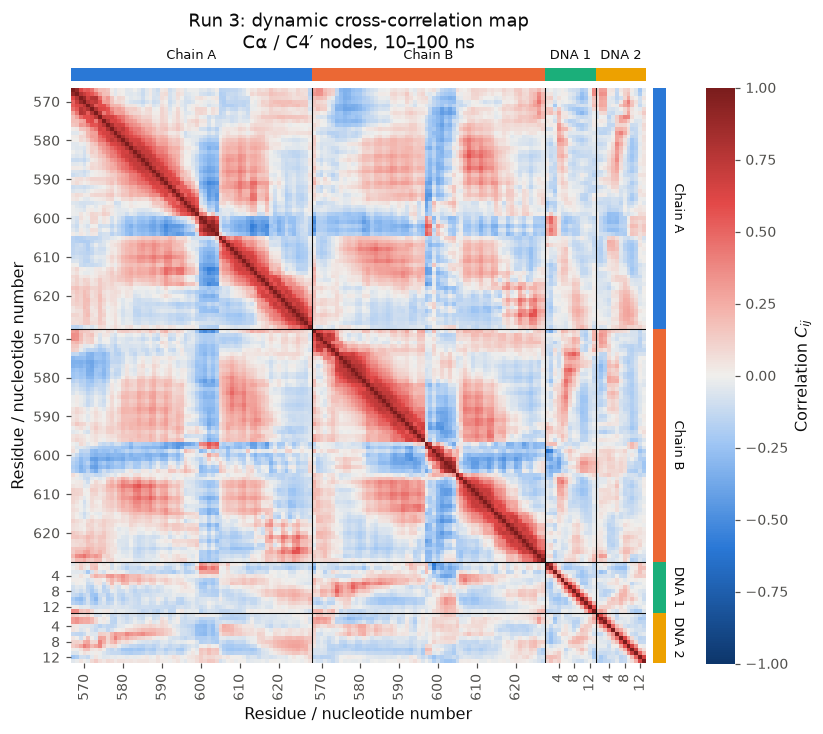

Mean correlation within / between chains:


,Chain A,Chain B,DNA 1,DNA 2
Chain A,0.103,0.007,-0.020,-0.004
Chain B,0.007,0.103,0.001,-0.025
DNA 1,-0.020,0.001,0.048,-0.007
DNA 2,-0.004,-0.025,-0.007,0.082


Most positively correlated protein–DNA pairs:


,protein,DNA,C_ij,distance (Å),protein residue at interface
0,B:N574,D1:G8,0.527,7.7,True
1,B:R578,D1:C7,0.516,8.0,True
2,A:K600,D1:A2,0.507,41.6,False
3,A:S601,D1:A2,0.480,40.8,False
4,B:V581,D1:A6,0.473,7.6,True
5,B:R578,D1:A6,0.468,9.1,True
6,B:N574,D1:C7,0.460,9.6,True
7,A:K603,D1:A2,0.453,39.7,False


Most anti-correlated protein–DNA pairs:


,protein,DNA,C_ij,distance (Å),protein residue at interface
0,B:L599,D1:C1,-0.581,28.1,False
1,B:L599,D1:A2,-0.542,25.1,False
2,B:D602,D1:A4,-0.403,15.5,False
3,B:S601,D1:A2,-0.391,20.7,False
4,B:K603,D1:A2,-0.387,16.2,False
5,B:K603,D1:A4,-0.377,11.9,False
6,B:K600,D1:C1,-0.376,26.9,False
7,B:S601,D1:C1,-0.370,23.6,False


Protein–DNA pairs with C > 0.5: 0.1%;  C < -0.5: 0.1%


In [8]:
# ---------------------------------------------------------------------------
# Figure 1: full DCCM
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.8, 6.8))
im = ax.imshow(dccm, cmap=CMAP_CORR, vmin=-1, vmax=1, interpolation="nearest")
decorate_axis(ax, "x", nodes_df)
decorate_axis(ax, "y", nodes_df)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xlabel("Residue / nucleotide number")
ax.set_ylabel("Residue / nucleotide number")
cb = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.09)
cb.set_label("Correlation $C_{ij}$")
cb.outline.set_visible(False)
ax.set_title(f"{RUN_NAME}: dynamic cross-correlation map\n"
             f"Cα / C4′ nodes, {t_win[0]:.0f}–{t_win[-1]:.0f} ns", pad=26)
save_fig(fig, "fig1_dccm")
plt.show()

# --- numbers behind the figure ---
# mean correlation inside and between chains (diagonal excluded within a chain)
block = pd.DataFrame(index=[i["short"] for i in SEG_INFO], columns=[i["short"] for i in SEG_INFO], dtype=float)
for a in SEG_INFO:
    for b in SEG_INFO:
        sub = dccm[a["start"]:a["stop"], b["start"]:b["stop"]]
        if a is b:
            sub = sub[~np.eye(len(sub), dtype=bool)]
        block.loc[a["short"], b["short"]] = sub.mean()
print("Mean correlation within / between chains:")
display(block.round(3))
block.to_csv(OUT_DIR / f"{TAG}_dccm_block_means.csv")

# strongest protein-DNA pairs (distance = between average node positions)
p_idx = np.where(nodes_df.molecule.values == "protein")[0]
d_idx = np.where(nodes_df.molecule.values == "DNA")[0]
pdb_ = dccm[np.ix_(p_idx, d_idx)]
dist_avg = np.linalg.norm(mean_xyz[:, None] - mean_xyz[None], axis=2)
def top_pairs(sign, n=8):
    flat = np.argsort(sign * pdb_, axis=None)[::-1][:n]
    i, j = np.unravel_index(flat, pdb_.shape)
    return pd.DataFrame({"protein": nodes_df.label.values[p_idx[i]], "DNA": nodes_df.label.values[d_idx[j]],
                         "C_ij": pdb_[i, j].round(3),
                         "distance (Å)": dist_avg[p_idx[i], d_idx[j]].round(1),
                         "protein residue at interface": nodes_df.interface.values[p_idx[i]]})
top_pos, top_neg = top_pairs(+1), top_pairs(-1)
print("Most positively correlated protein–DNA pairs:"); display(top_pos)
print("Most anti-correlated protein–DNA pairs:");       display(top_neg)
pd.concat([top_pos.assign(kind="positive"), top_neg.assign(kind="negative")]).to_csv(
    OUT_DIR / f"{TAG}_dccm_top_protein_dna_pairs.csv", index=False)
pd.DataFrame(dccm, index=nodes_df.label, columns=nodes_df.label).round(4).to_csv(OUT_DIR / f"{TAG}_dccm_matrix.csv")
print(f"Protein–DNA pairs with C > 0.5: {(pdb_ > 0.5).mean() * 100:.1f}%;  C < -0.5: {(pdb_ < -0.5).mean() * 100:.1f}%")

**Figure 1.** *Dynamic cross-correlation map of the TCF4–DNA complex for this run, computed from C$\alpha$ (protein) and C4′ (DNA) fluctuations over the analysis window after iterative least-squares superposition on the average structure. Red: correlated (same-direction) motion; blue: anti-correlated; grey: uncorrelated. Lines and coloured bands separate TCF4 chains A and B and DNA strands 1 and 2.*

**Interpretation** **
### Interpretation — Figure 1: DCCM (Run 3)

Both TCF4 chains exhibit localized correlated motions, with identical mean intrachain correlations (**0.103**). The weak positive interchain correlation (**0.007**) indicates limited overall coordination between the monomers.

Protein–DNA correlations are weak on average but show localized positive coupling at the interface, particularly B:N574–DNA1:G8 (**C = 0.527**) and B:R578–DNA1:C7 (**C = 0.516**). Long-range anti-correlations, such as B:L599–DNA1:C1 (**C = −0.581**), suggest coordinated opposing fluctuations between distant regions.

The DNA strands exhibit weak average interstrand correlation (**−0.007**), indicating that their motions are not uniformly correlated.

**Overall:** Run 3 displays region-specific protein–DNA coupling and heterogeneous collective motions rather than rigid-body movement of the entire complex.

### Figure 2 — Protein–DNA coupling
Top: the protein × DNA block of the DCCM. Bottom: the **DNA-coupling index** of every protein residue, $\bar C_{i,\mathrm{DNA}}=\frac{1}{N_\mathrm{DNA}}\sum_{j\in\mathrm{DNA}}C_{ij}$, aligned column-by-column with the map above.

  saved run3_fig2_protein_dna_coupling.png / .pdf


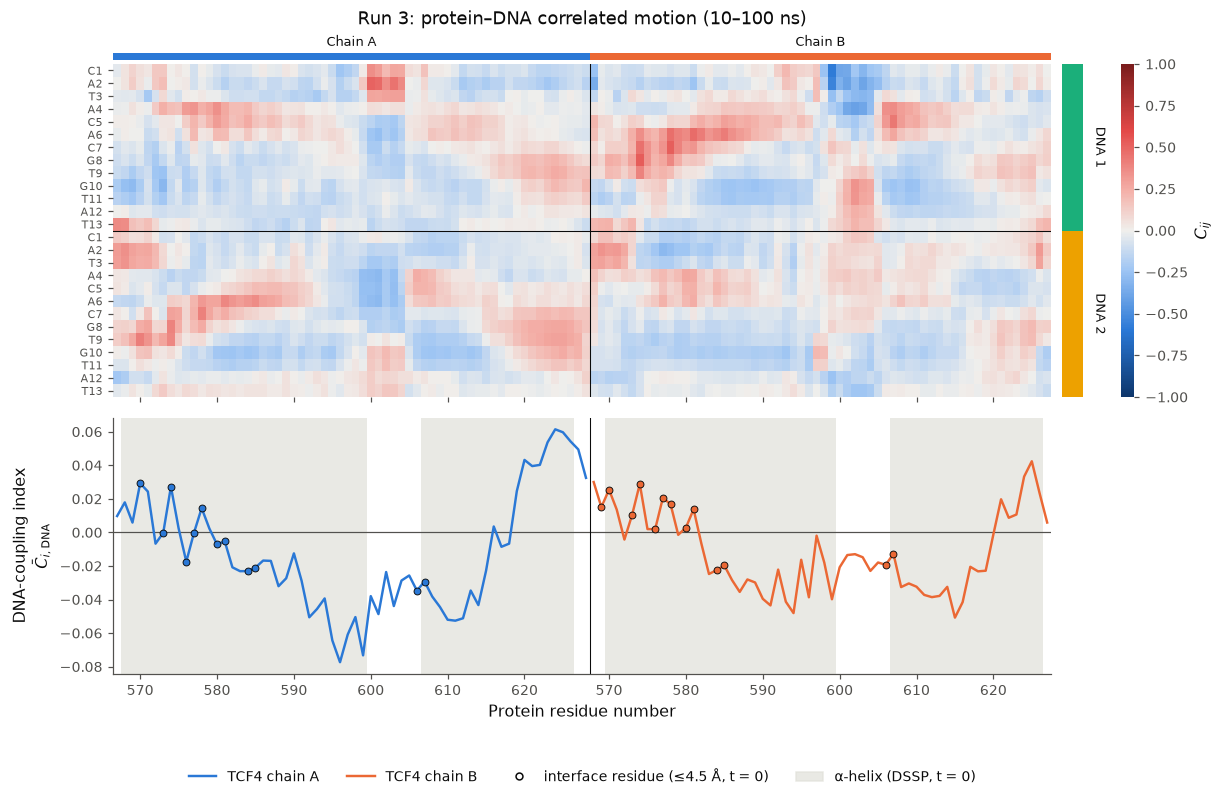

TCF4 chain A: most DNA-coupled residues A:Q624(+0.06), A:V625(+0.06), A:Q623(+0.05), A:R626(+0.05), A:E627(+0.05), A:S620(+0.04)  | least: A:V595(-0.06), A:L599(-0.07), A:Q596(-0.08)
TCF4 chain B: most DNA-coupled residues B:V625(+0.04), B:Q624(+0.03), B:M568(+0.03), B:N574(+0.03*), B:R570(+0.03*), B:R626(+0.02)  | least: B:L591(-0.04), B:M594(-0.05), B:V615(-0.05)
(* = interface residue in the starting structure)
Mean coupling: interface residues -0.000, non-interface -0.015


In [9]:
# ---------------------------------------------------------------------------
# Figure 2: protein x DNA correlation block + per-residue DNA-coupling index
# ---------------------------------------------------------------------------
prot_df = nodes_df.iloc[p_idx].reset_index(drop=True)
dna_df  = nodes_df.iloc[d_idx].reset_index(drop=True)
coupling = pdb_.mean(axis=1)                       # DNA-coupling index per protein residue

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.2), sharex=True,
                               gridspec_kw=dict(height_ratios=[1.3, 1], hspace=0.07))
im = ax1.imshow(pdb_.T, aspect="auto", cmap=CMAP_CORR, vmin=-1, vmax=1, interpolation="nearest")
decorate_axis(ax1, "x", prot_df)
decorate_axis(ax1, "y", dna_df, dna_all=True)
ax1.tick_params(axis="y", labelsize=7.5)
for s in ax1.spines.values():
    s.set_visible(False)
cax = ax1.inset_axes([1.075, 0.0, 0.014, 1.0])
cb = fig.colorbar(im, cax=cax)
cb.set_label("$C_{ij}$")
cb.outline.set_visible(False)
ax1.set_title(f"{RUN_NAME}: protein–DNA correlated motion ({t_win[0]:.0f}–{t_win[-1]:.0f} ns)", pad=26)

# bottom panel: helices shaded, one line per chain, interface residues marked
for k, (a, b) in enumerate(helix_runs(prot_df.ss.values)):
    ax2.axvspan(a - 0.5, b - 0.5, color=GRID, alpha=0.7, lw=0, zorder=0)
ax2.axhline(0, color=INK2, lw=0.8, zorder=1)
for info, s, e in chain_spans(prot_df):
    x = np.arange(s, e)
    ax2.plot(x, coupling[s:e], color=info["color"], lw=1.6, zorder=2)
    iface_m = prot_df.interface.values[s:e]
    ax2.plot(x[iface_m], coupling[s:e][iface_m], "o", ms=4.5, mfc=info["color"], mec=INK, mew=0.6, zorder=3)
    ax2.axvline(s - 0.5, color=INK, lw=0.7) if s else None
ax2.set_ylabel("DNA-coupling index\n$\\bar C_{i,\\mathrm{DNA}}$")
ax2.set_xlabel("Protein residue number")
ax2.set_xlim(-0.5, len(prot_df) - 0.5)
handles = [Line2D([], [], color=i["color"], lw=1.6, label=i["label"]) for i, _, _ in chain_spans(prot_df)]
handles += [Line2D([], [], ls="", marker="o", ms=4.5, mfc="white", mec=INK, label=f"interface residue (≤{INTERFACE_CUTOFF:g} Å, t = 0)"),
            Patch(color=GRID, alpha=0.7, label="α-helix (DSSP, t = 0)")]
ax2.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=4)
save_fig(fig, "fig2_protein_dna_coupling")
plt.show()

cpl = prot_df.assign(coupling=coupling.round(3))
cpl[["segid", "resid", "resname", "label", "interface", "ss", "coupling"]].to_csv(
    OUT_DIR / f"{TAG}_dna_coupling_index.csv", index=False)
for info, s, e in chain_spans(prot_df):
    sub = cpl.iloc[s:e].sort_values("coupling", ascending=False)
    print(f"{info['label']}: most DNA-coupled residues "
          + ", ".join(f"{r.label}({r.coupling:+.2f}{'*' if r.interface else ''})" for r in sub.head(6).itertuples())
          + f"  | least: " + ", ".join(f"{r.label}({r.coupling:+.2f})" for r in sub.tail(3).itertuples()))
print("(* = interface residue in the starting structure)")
print(f"Mean coupling: interface residues {coupling[prot_df.interface.values].mean():+.3f}, "
      f"non-interface {coupling[~prot_df.interface.values].mean():+.3f}")

**Figure 2.** *(Top) Correlation $C_{ij}$ between every TCF4 residue (columns) and every nucleotide (rows, base and number), for this run. (Bottom) DNA-coupling index — the mean of each column above — for chain A and chain B; dots mark interface residues (heavy atom within 4.5 Å of DNA in the starting structure); grey bands mark α-helices.*

**Interpretation** *:* ### Interpretation — Figure 2: Protein–DNA Coupling (Run 3)

The strongest positive DNA coupling occurs near **residues 620–627**, particularly in Chain A (Q624, V625, R626), while the central helical regions show predominantly negative coupling.

Interface residues show stronger coupling than non-interface residues (mean **0.000 vs. −0.015**), although both averages are weak.

Chains A and B exhibit similar overall trends but different coupling strengths, indicating **partially asymmetric dynamics**.

Some non-interface residues also exhibit appreciable correlations with DNA, suggesting possible long-range dynamical coordination.

**Overall:** Run 3 shows region-specific, asymmetric protein–DNA coupling, with the strongest positive average coupling near the C-terminal region of both chains.

### Figure 3 — Is the DCCM converged within this run?

  saved run3_fig3_dccm_convergence.png / .pdf


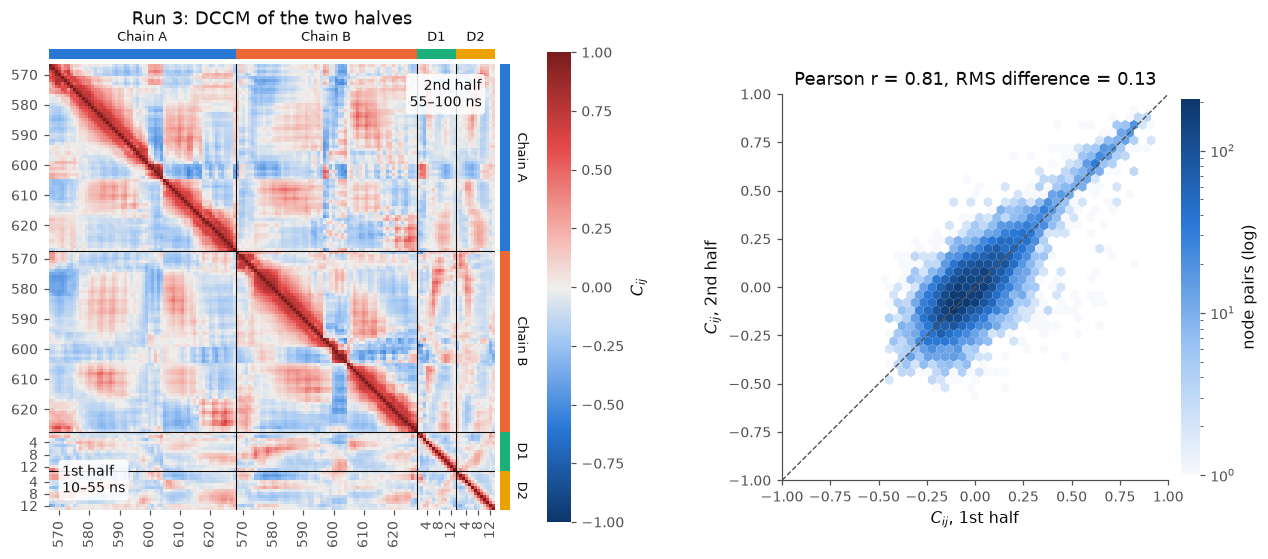

Split-half agreement of the DCCM: r = 0.808, RMS difference = 0.128


In [10]:
# ---------------------------------------------------------------------------
# Figure 3: split-half DCCM (lower triangle = 1st half, upper = 2nd half)
# ---------------------------------------------------------------------------
half = F // 2
d1, d2 = dccm_from_cov(covariance(X_al[:half])), dccm_from_cov(covariance(X_al[half:]))
iu = np.triu_indices(N, k=1)
r_half = float(np.corrcoef(d1[iu], d2[iu])[0, 1])
rms_half = float(np.sqrt(np.mean((d1[iu] - d2[iu]) ** 2)))
combo = np.tril(d1, -1) + np.triu(d2, 1) + np.eye(N)

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13.5, 5.8), gridspec_kw=dict(width_ratios=[1.25, 1], wspace=0.45))
im = axA.imshow(combo, cmap=CMAP_CORR, vmin=-1, vmax=1, interpolation="nearest")
decorate_axis(axA, "x", nodes_df)
decorate_axis(axA, "y", nodes_df)
for s in axA.spines.values():
    s.set_visible(False)
box = dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85)
axA.text(0.03, 0.03, f"1st half\n{t_win[0]:.0f}–{t_win[half - 1]:.0f} ns", transform=axA.transAxes,
         ha="left", va="bottom", fontsize=9, bbox=box)
axA.text(0.97, 0.97, f"2nd half\n{t_win[half]:.0f}–{t_win[-1]:.0f} ns", transform=axA.transAxes,
         ha="right", va="top", fontsize=9, bbox=box)
cb = fig.colorbar(im, ax=axA, fraction=0.045, pad=0.1)
cb.set_label("$C_{ij}$"); cb.outline.set_visible(False)
axA.set_title(f"{RUN_NAME}: DCCM of the two halves", pad=26)

hb = axB.hexbin(d1[iu], d2[iu], gridsize=45, cmap=CMAP_OVL, mincnt=1, bins="log", extent=(-1, 1, -1, 1), lw=0)
axB.plot([-1, 1], [-1, 1], color=INK2, lw=0.9, ls="--")
axB.set_xlim(-1, 1); axB.set_ylim(-1, 1); axB.set_aspect("equal")
axB.set_xlabel("$C_{ij}$, 1st half"); axB.set_ylabel("$C_{ij}$, 2nd half")
axB.set_title(f"Pearson r = {r_half:.2f}, RMS difference = {rms_half:.2f}")
cb2 = fig.colorbar(hb, ax=axB, fraction=0.045, pad=0.03)
cb2.set_label("node pairs (log)"); cb2.outline.set_visible(False)
save_fig(fig, "fig3_dccm_convergence")
plt.show()
print(f"Split-half agreement of the DCCM: r = {r_half:.3f}, RMS difference = {rms_half:.3f}")

**Figure 3.** *Convergence of the DCCM within this run. (Left) Lower triangle: DCCM from the first half of the window; upper triangle: second half. (Right) Every node pair's correlation in the two halves; the dashed line is perfect agreement.*

**Interpretation** *:*

The two trajectory halves (10–55 ns and 55–100 ns) show **strong agreement**, with a Pearson correlation of **r = 0.808** and an RMS difference of **0.128**.

This indicates that the overall correlated-motion patterns are reasonably consistent, although some local differences suggest time-dependent fluctuations.

**Overall:** Run 3 shows good DCCM consistency, but its convergence is weaker than Runs 1 and 2 (r = 0.900), indicating greater variability in correlated motions.

## 6. Principal component analysis
### Figure 4 — Eigenvalue spectrum

  saved run3_fig4_pca_spectrum.png / .pdf


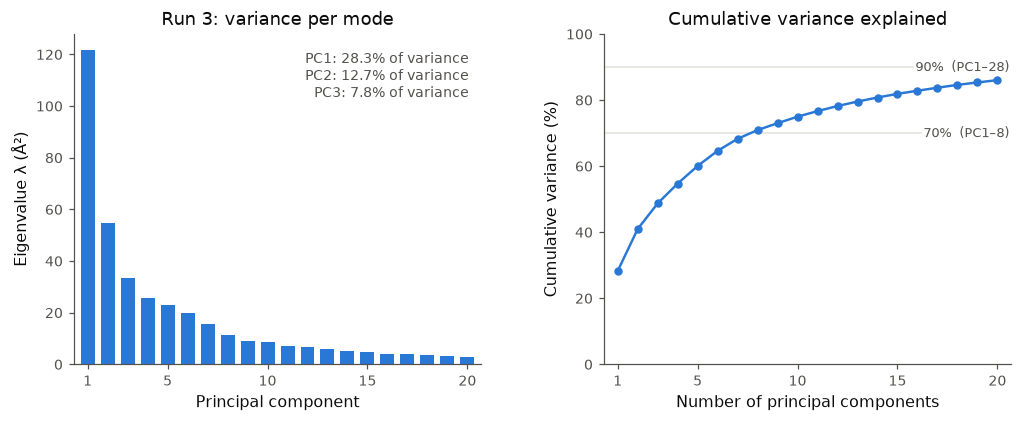

,PC,eigenvalue_A2,variance_%,cumulative_%
0,1,121.807,28.27,28.27
1,2,54.758,12.71,40.98
2,3,33.438,7.76,48.74
3,4,25.831,6.00,54.74
4,5,22.992,5.34,60.07


PCs needed for 50 / 70 / 90% of the variance: 4 / 8 / 28  (of 444)


In [11]:
# ---------------------------------------------------------------------------
# Figure 4: PCA eigenvalue spectrum
# ---------------------------------------------------------------------------
evals, evecs = pca_from_cov(cov)
frac = evals / evals.sum()
cumf = np.cumsum(frac)
K = min(N_PCS_REPORT, len(evals))
proj = dX @ evecs[:, :K]                                    # projections p_k(t), Å
n_for = {p: int(np.searchsorted(cumf, p / 100) + 1) for p in (50, 70, 90)}

kmax = 20
pcs = np.arange(1, kmax + 1)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw=dict(wspace=0.3))
a.bar(pcs, evals[:kmax], width=0.7, color=SERIES[0])
a.text(0.97, 0.95, "\n".join(f"PC{k + 1}: {frac[k] * 100:.1f}% of variance" for k in range(3)),
       transform=a.transAxes, ha="right", va="top", fontsize=9, color=INK2)
a.set_xlabel("Principal component"); a.set_ylabel("Eigenvalue λ (Å²)")
a.set_xticks([1, 5, 10, 15, 20]); a.set_xlim(0.3, kmax + 0.7)
a.set_title(f"{RUN_NAME}: variance per mode")
b.plot(pcs, cumf[:kmax] * 100, marker="o", ms=4.5, color=SERIES[0])
for p in (70, 90):
    b.axhline(p, color=GRID, lw=1, zorder=0)
    b.text(kmax + 0.6, p, f"{p}%  (PC1–{n_for[p]})", va="center", ha="right", fontsize=8.5, color=INK2,
           bbox=dict(fc="white", ec="none", pad=1))
b.set_ylim(0, 100); b.set_xlim(0.3, kmax + 0.7); b.set_xticks([1, 5, 10, 15, 20])
b.set_xlabel("Number of principal components"); b.set_ylabel("Cumulative variance (%)")
b.set_title("Cumulative variance explained")
save_fig(fig, "fig4_pca_spectrum")
plt.show()

pca_table = pd.DataFrame({"PC": np.arange(1, K + 1), "eigenvalue_A2": evals[:K].round(3),
                          "variance_%": (frac[:K] * 100).round(2), "cumulative_%": (cumf[:K] * 100).round(2)})
pca_table.to_csv(OUT_DIR / f"{TAG}_pca_variance.csv", index=False)
display(pca_table.head(5))
print(f"PCs needed for 50 / 70 / 90% of the variance: {n_for[50]} / {n_for[70]} / {n_for[90]}  (of {3 * N})")

**Figure 4.** *PCA eigenvalue spectrum for this run (C$\alpha$/C4′ covariance over the analysis window). (Left) Variance along the first 20 modes, with the percentage of the total for PC1–PC3. (Right) Cumulative variance; grey lines mark 70% and 90%.*

**Interpretation** *:* 
PC1 dominates the collective motions, explaining **28.27%** of total variance, followed by PC2 (12.71%) and PC3 (7.76%). Together, these three modes account for **48.74%** of the fluctuations.

The first **4, 8, and 28 principal components** are needed to capture approximately 50%, 70%, and 90% of the total variance, respectively.

**Overall:** Run 3 is dominated by a few large-scale collective motions, with the first 8 PCs forming a reasonable 70%-variance essential subspace. Higher modes still contribute substantially to the overall dynamics.

### Figure 5 — Conformational sampling along PC1 and PC2

  saved run3_fig5_pc_landscape.png / .pdf


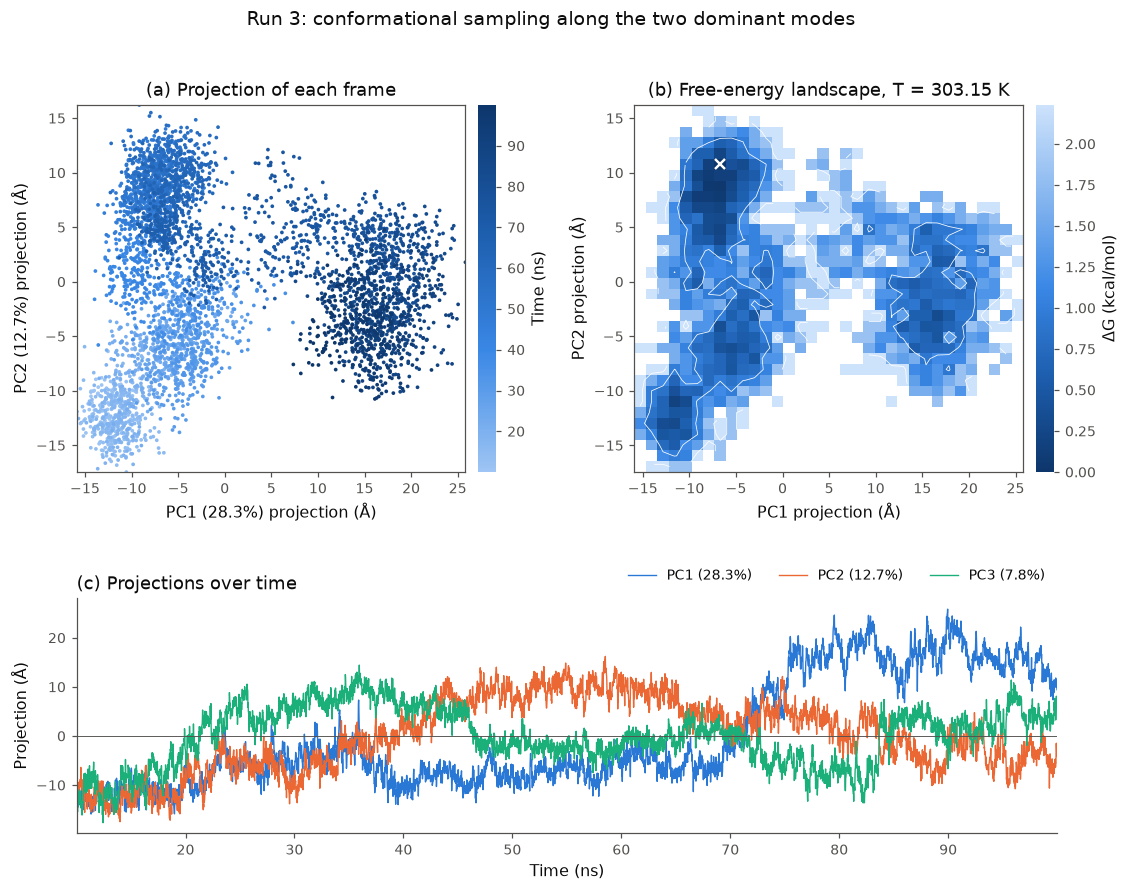

Global minimum of the landscape at PC1 = -6.7 Å, PC2 = 10.8 Å
Range sampled: PC1 -15.9 to 25.8 Å, PC2 -17.4 to 16.2 Å
Fraction of frames within 1 kcal/mol of the minimum: 70.2%


In [12]:
# ---------------------------------------------------------------------------
# Figure 5: PC1-PC2 projections (coloured by time), free-energy landscape, PC time series
# ---------------------------------------------------------------------------
G, xe, ye, P2 = free_energy_2d(proj[:, 0], proj[:, 1], temperature_K, bins=fel_bins(F))
xc, yc = (xe[:-1] + xe[1:]) / 2, (ye[:-1] + ye[1:]) / 2
imin = np.unravel_index(np.nanargmin(G), G.shape)

fig = plt.figure(figsize=(11.5, 8.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1.25, 0.8], hspace=0.42, wspace=0.32)
ax_s = fig.add_subplot(gs[0, 0])
ax_f = fig.add_subplot(gs[0, 1], sharex=ax_s, sharey=ax_s)
ax_t = fig.add_subplot(gs[1, :])

sc = ax_s.scatter(proj[:, 0], proj[:, 1], c=t_win, cmap=CMAP_TIME, s=6, lw=0, rasterized=True)
cb = fig.colorbar(sc, ax=ax_s, fraction=0.05, pad=0.03); cb.set_label("Time (ns)"); cb.outline.set_visible(False)
ax_s.set_xlabel(f"PC1 ({frac[0] * 100:.1f}%) projection (Å)"); ax_s.set_ylabel(f"PC2 ({frac[1] * 100:.1f}%) projection (Å)")
ax_s.set_title("(a) Projection of each frame")

gmax = np.nanmax(G)
pcm = ax_f.pcolormesh(xe, ye, G, cmap=CMAP_FEL, vmin=0, vmax=gmax, rasterized=True)
levels = np.arange(1, gmax, 1.0)
if len(levels):
    ax_f.contour(xc, yc, G, levels=levels, colors="white", linewidths=0.5)
ax_f.plot(xc[imin[1]], yc[imin[0]], marker="x", color="white", ms=7, mew=1.6)
cb = fig.colorbar(pcm, ax=ax_f, fraction=0.05, pad=0.03); cb.set_label("ΔG (kcal/mol)"); cb.outline.set_visible(False)
ax_f.set_xlabel(f"PC1 projection (Å)"); ax_f.set_ylabel(f"PC2 projection (Å)")
ax_f.set_title(f"(b) Free-energy landscape, T = {temperature_K:g} K")
for ax in (ax_s, ax_f):
    ax.spines["top"].set_visible(True); ax.spines["right"].set_visible(True)

for k in range(min(3, K)):
    ax_t.plot(t_win, proj[:, k], color=SERIES[k], lw=0.9, label=f"PC{k + 1} ({frac[k] * 100:.1f}%)")
ax_t.axhline(0, color=INK2, lw=0.6)
ax_t.set_xlabel("Time (ns)"); ax_t.set_ylabel("Projection (Å)")
ax_t.set_xlim(t_win[0], t_win[-1])
ax_t.legend(ncol=3, loc="upper right", bbox_to_anchor=(1.0, 1.18))
ax_t.set_title("(c) Projections over time", loc="left")
fig.suptitle(f"{RUN_NAME}: conformational sampling along the two dominant modes", y=0.98)
save_fig(fig, "fig5_pc_landscape")
plt.show()

proj_df = pd.DataFrame(proj, columns=[f"PC{k + 1}_A" for k in range(K)]).round(4)
proj_df.insert(0, "time_ns", t_win.round(4))
proj_df.to_csv(OUT_DIR / f"{TAG}_pc_projections.csv", index=False)
print(f"Global minimum of the landscape at PC1 = {xc[imin[1]]:.1f} Å, PC2 = {yc[imin[0]]:.1f} Å")
print(f"Range sampled: PC1 {proj[:, 0].min():.1f} to {proj[:, 0].max():.1f} Å, "
      f"PC2 {proj[:, 1].min():.1f} to {proj[:, 1].max():.1f} Å")
print(f"Fraction of frames within 1 kcal/mol of the minimum: "
      f"{P2.T[np.nan_to_num(G, nan=99) <= 1.0].sum() * 100:.1f}%")

**Figure 5.** *Sampling of the two dominant collective motions in this run. (a) Each frame projected onto PC1 and PC2, coloured by simulation time. (b) Pseudo free-energy landscape $G=-k_BT\ln P(\mathrm{PC1},\mathrm{PC2})$ (white contours every 1 kcal/mol; × marks the global minimum). (c) Projections on PC1–PC3 versus time.*

**Interpretation** *:* 

The PCA landscape reveals **multiple conformational basins**, with the global free-energy minimum at **PC1 = −6.7 Å and PC2 = 10.8 Å**. Approximately **70.2%** of frames lie within 1 kcal/mol of the minimum.

The time-colored projections show a progressive shift between conformational regions, particularly along PC1. A major transition occurs around **70–75 ns**, with limited return to the earlier basin.

**Overall:** Run 3 samples several conformational states but shows predominantly one-way transitions rather than repeated movement between basins. This suggests incomplete conformational sampling and possible PCA convergence limitations.

### Figure 6 — Which residues and nucleotides carry each mode?

  saved run3_fig6_pc_participation.png / .pdf


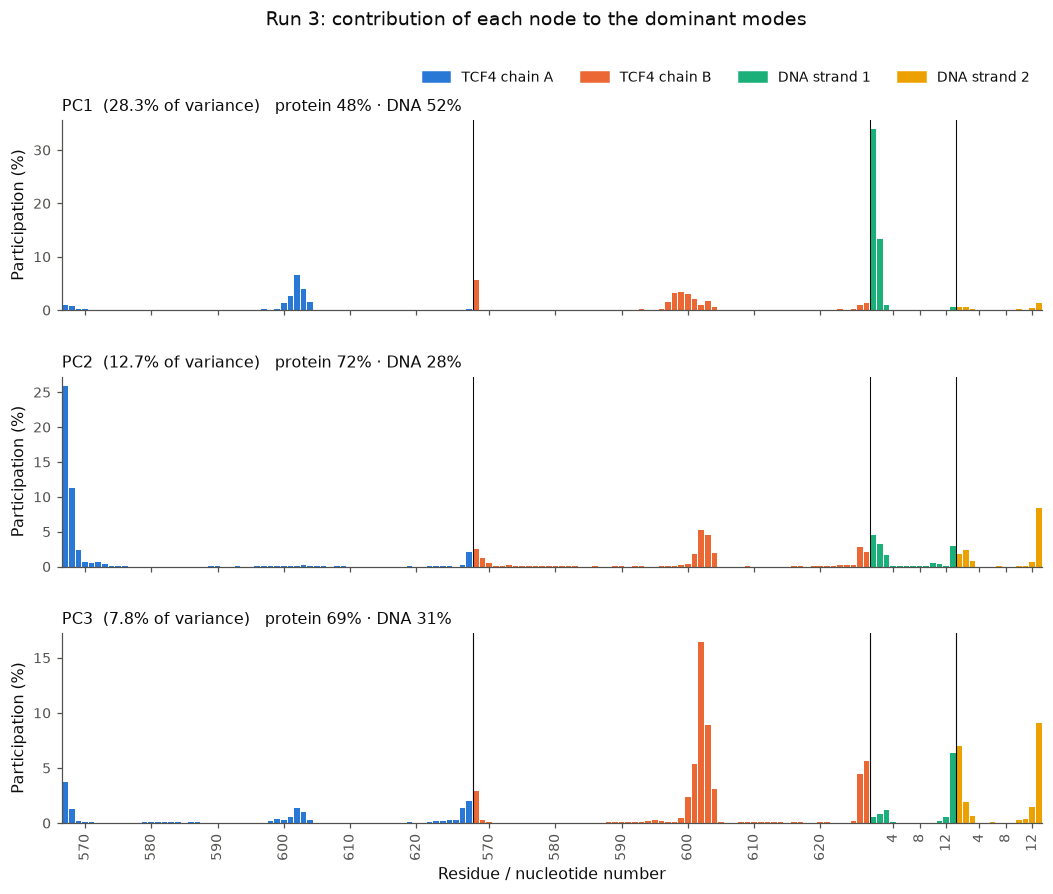

,PC,variance_%,protein_%,DNA_%,top nodes
0,1,28.27,47.5,52.5,"D1:C1 (33.9%), D1:A2 (13.4%), A:D602 (6.5%), B..."
1,2,12.71,72.1,27.9,"A:H567 (25.9%), A:M568 (11.3%), D2:T13 (8.4%),..."
2,3,7.76,69.1,30.9,"B:D602 (16.4%), D2:T13 (9.1%), B:K603 (8.9%), ..."


In [13]:
# ---------------------------------------------------------------------------
# Figure 6: per-node participation in PC1-PC3
# ---------------------------------------------------------------------------
n_show = min(3, K)
part = (evecs[:, :n_show].reshape(N, 3, n_show) ** 2).sum(axis=1)     # (N, n_show); each column sums to 1
is_prot = nodes_df.molecule.values == "protein"
node_colors = [SEG_BY_ID[s]["color"] for s in nodes_df.segid]

fig, axes = plt.subplots(n_show, 1, figsize=(11.5, 2.5 * n_show + 0.8), sharex=True,
                         gridspec_kw=dict(hspace=0.35))
axes = np.atleast_1d(axes)
part_rows = []
for k, ax in enumerate(axes):
    ax.bar(np.arange(N), part[:, k] * 100, width=0.85, color=node_colors, lw=0)
    for _, s, _ in chain_spans(nodes_df)[1:]:
        ax.axvline(s - 0.5, color=INK, lw=0.7)
    share_p = part[is_prot, k].sum() * 100
    top = np.argsort(part[:, k])[::-1][:5]
    ax.set_title(f"PC{k + 1}  ({frac[k] * 100:.1f}% of variance)   protein {share_p:.0f}% · DNA {100 - share_p:.0f}%",
                 loc="left", fontsize=10.5)
    ax.set_ylabel("Participation (%)")
    ax.set_xlim(-0.5, N - 0.5)
    part_rows.append({"PC": k + 1, "variance_%": round(frac[k] * 100, 2), "protein_%": round(share_p, 1),
                      "DNA_%": round(100 - share_p, 1),
                      "top nodes": ", ".join(f"{nodes_df.label[i]} ({part[i, k] * 100:.1f}%)" for i in top)})
decorate_axis(axes[-1], "x", nodes_df, band=False)
axes[-1].set_xlabel("Residue / nucleotide number")
axes[0].legend(handles=[Patch(color=i["color"], label=i["label"]) for i in SEG_INFO],
               ncol=len(SEG_INFO), loc="lower right", bbox_to_anchor=(1.0, 1.12))
fig.suptitle(f"{RUN_NAME}: contribution of each node to the dominant modes", y=1.0 + 0.02 * (3 - n_show))
save_fig(fig, "fig6_pc_participation")
plt.show()

part_df = pd.DataFrame(part_rows)
display(part_df)
pd.concat([nodes_df[["segid", "resid", "resname", "label"]],
           pd.DataFrame(part * 100, columns=[f"PC{k + 1}_participation_%" for k in range(n_show)]).round(3)],
          axis=1).to_csv(OUT_DIR / f"{TAG}_pc_participation.csv", index=False)

**Figure 6.** *Participation of every node in PC1–PC3 for this run (squared eigenvector components summed over x, y, z; each panel sums to 100%). Colours identify TCF4 chains A/B and DNA strands 1/2; panel titles give the protein/DNA share of each mode.*

**Interpretation** *:* 

PC1 is shared between protein (47.5%) and DNA (52.5%), but is strongly influenced by the DNA1 terminus, particularly C1 (33.9%). This suggests that **localized terminal motion**, rather than uniform motion of the entire complex, contributes substantially to PC1.

PC2 and PC3 are predominantly protein-driven (72.1% and 69.1%), with major contributions from A:H567 and A:M568 in PC2, and B:D602 and B:K603 in PC3.

**Overall:** Run 3 exhibits localized DNA-terminal and protein-region motions rather than uniformly distributed global fluctuations. Specific motions such as HLH bending, scissoring, or DNA bending require confirmation using the PCA motion files in VMD.

### Figure 7 — Is the PCA converged within this run?
Also writes `<run>_PC1_motion.pdb` … `PC3`: multi-model PDBs of the node atoms moving along each mode (from the 2.5th to the 97.5th percentile of the projection and back). Open them in VMD (`vmd run2_PC1_motion.pdb`, representation *Trace* or *Tube*, then play the animation) together with `step3_input.pdb` to see and name each motion.

  saved run3_fig7_pca_convergence.png / .pdf


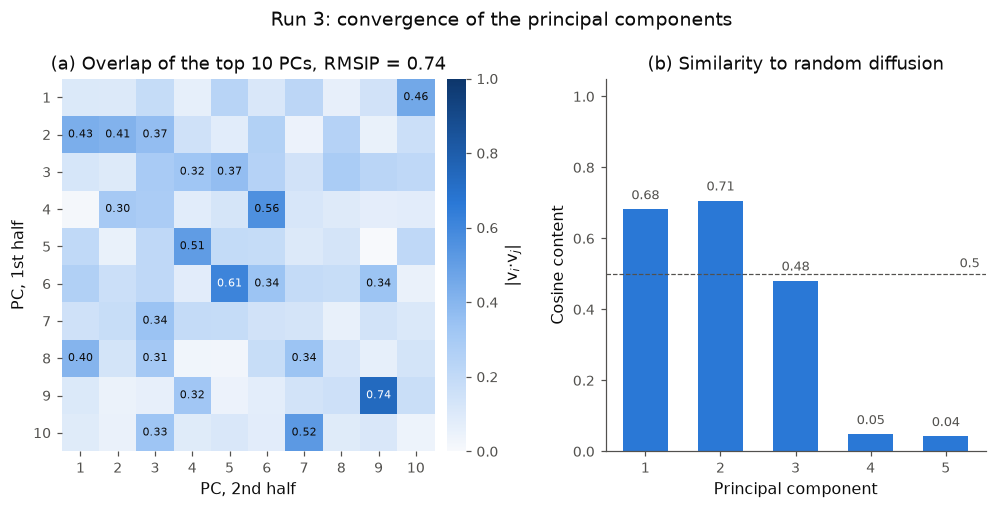

RMSIP (top 10 PCs, 1st vs 2nd half): 0.742
Cosine content: PC1 0.68, PC2 0.71, PC3 0.48, PC4 0.05, PC5 0.04
  wrote run3_PC1_motion.pdb  (PC1 amplitude -12.9 to 20.9 Å)
  wrote run3_PC2_motion.pdb  (PC2 amplitude -13.9 to 12.0 Å)
  wrote run3_PC3_motion.pdb  (PC3 amplitude -12.1 to 9.7 Å)


In [14]:
# ---------------------------------------------------------------------------
# Figure 7: subspace overlap of the two halves + cosine content; PC motion files for VMD
# ---------------------------------------------------------------------------
_, V1 = pca_from_cov(covariance(X_al[:half]))
_, V2 = pca_from_cov(covariance(X_al[half:]))
rmsip_half, overlap = rmsip(V1, V2, K)
n_cc = min(5, K)
cosc = np.array([cosine_content(proj[:, k], k + 1) for k in range(n_cc)])

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw=dict(width_ratios=[1.1, 1], wspace=0.35))
im = a.imshow(overlap, cmap=CMAP_OVL, vmin=0, vmax=1)
for i in range(K):
    for j in range(K):
        if overlap[i, j] >= 0.3:
            a.text(j, i, f"{overlap[i, j]:.2f}", ha="center", va="center", fontsize=7,
                   color="white" if overlap[i, j] > 0.6 else INK)
a.set_xticks(range(K)); a.set_xticklabels(range(1, K + 1))
a.set_yticks(range(K)); a.set_yticklabels(range(1, K + 1))
a.set_xlabel("PC, 2nd half"); a.set_ylabel("PC, 1st half")
for s in a.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=a, fraction=0.045, pad=0.03); cb.set_label("|v$_i$·v$_j$|"); cb.outline.set_visible(False)
a.set_title(f"(a) Overlap of the top {K} PCs, RMSIP = {rmsip_half:.2f}")

b.bar(np.arange(1, n_cc + 1), cosc, width=0.6, color=SERIES[0])
for k, c in enumerate(cosc):
    b.text(k + 1, c + 0.02, f"{c:.2f}", ha="center", va="bottom", fontsize=8.5, color=INK2)
b.axhline(0.5, color=INK2, lw=0.8, ls="--")
b.text(n_cc + 0.45, 0.51, "0.5", ha="right", va="bottom", fontsize=8.5, color=INK2)
b.set_ylim(0, 1.05); b.set_xticks(range(1, n_cc + 1))
b.set_xlabel("Principal component"); b.set_ylabel("Cosine content")
b.set_title("(b) Similarity to random diffusion")
fig.suptitle(f"{RUN_NAME}: convergence of the principal components", y=1.02)
save_fig(fig, "fig7_pca_convergence")
plt.show()
print(f"RMSIP (top {K} PCs, 1st vs 2nd half): {rmsip_half:.3f}")
print("Cosine content: " + ", ".join(f"PC{k + 1} {c:.2f}" for k, c in enumerate(cosc)))

# --- PC motion movies for VMD (node atoms only) ---
mode_universe = mda.Merge(nodes)
for k in range(min(3, K)):
    v = evecs[:, k].reshape(N, 3)
    lo, hi = np.percentile(proj[:, k], [2.5, 97.5])
    amp = np.concatenate([np.linspace(lo, hi, 15), np.linspace(hi, lo, 15)[1:-1]])
    traj = (mean_xyz[None] + amp[:, None, None] * v[None]).astype(np.float32)
    mode_universe.load_new(traj, order="fac")
    path = OUT_DIR / f"{TAG}_PC{k + 1}_motion.pdb"
    with mda.Writer(str(path), n_atoms=N, multiframe=True) as w:
        for _ in mode_universe.trajectory:
            w.write(mode_universe.atoms)
    print(f"  wrote {path.name}  (PC{k + 1} amplitude {lo:.1f} to {hi:.1f} Å)")

**Figure 7.** *Convergence of the PCA within this run. (a) Absolute inner products between the top 10 eigenvectors of the first and second halves of the window, with their RMSIP. (b) Cosine content of the projections on PC1–PC5 over the full window; values near 1 indicate random-diffusion-like behaviour (unconverged sampling along that mode).*

**Interpretation** *:* 

The RMSIP of **0.742** indicates moderate-to-strong overlap between the principal component subspaces of the two trajectory halves, suggesting partial convergence of collective motions.

However, PC1 and PC2 exhibit high cosine contents (**0.68 and 0.71**), indicating diffusion-like behavior and potentially insufficient sampling. PC3 shows borderline behavior (0.48), while PC4 and PC5 have low values (0.05 and 0.04).

**Overall:** Run 3 shows reasonable PCA subspace consistency, but convergence remains incomplete, particularly for the dominant PC1 and PC2 motions. Longer simulations may be needed to establish reliable conformational sampling.

## 7. Save results and summary for this run

In [15]:
# ---------------------------------------------------------------------------
# 7. Persist numerical results and print a summary
# ---------------------------------------------------------------------------
np.savez_compressed(OUT_DIR / f"{TAG}_pca_dccm_results.npz",
                    time_ns=t_win, dccm=dccm, dccm_half1=d1, dccm_half2=d2, eigenvalues=evals,
                    eigenvectors=evecs[:, :K], projections=proj, mean_structure=mean_xyz,
                    rmsf_nodes=rmsf_nodes, labels=as_str(nodes_df.label))
summary = {
    "run": RUN_LABEL, "tag": TAG, "folder": str(WORK_DIR),
    "segments": len(seg_paths), "trajectory_ns": round(total_ns, 3),
    "window_ns": [round(float(t_win[0]), 3), round(float(t_win[-1]), 3)],
    "frames_analysed": int(F), "frame_spacing_ps": FRAME_DT_PS * STRIDE, "temperature_K": temperature_K,
    "nodes": int(N), "fit_nodes": int(len(fit_idx)), "alignment_iterations": int(n_iter),
    "fit_rmsd_to_average_A": [round(float(fit_rmsd.mean()), 3), round(float(fit_rmsd.std()), 3)],
    "dccm_block_means": block.round(4).to_dict(),
    "dccm_split_half_pearson_r": round(r_half, 4), "dccm_split_half_rms_diff": round(rms_half, 4),
    "pca_variance_percent": [round(float(x), 3) for x in frac[:K] * 100],
    "pcs_for_50_70_90_percent": [n_for[50], n_for[70], n_for[90]],
    "pca_split_half_rmsip": round(rmsip_half, 4),
    "cosine_content": [round(float(c), 4) for c in cosc],
    "pc_protein_share_percent": [r["protein_%"] for r in part_rows],
    "top_dna_coupled_residues": cpl.sort_values("coupling", ascending=False).head(10)[["label", "coupling"]].values.tolist(),
}
with open(OUT_DIR / f"{TAG}_summary.json", "w") as fh:
    json.dump(summary, fh, indent=2, default=float)

print(f"===== {RUN_NAME}: summary =====")
print(f"Window {summary['window_ns'][0]:.1f}-{summary['window_ns'][1]:.1f} ns, {F} frames, {N} nodes")
print(f"DCCM  : chain A-B mean {block.iloc[0, 1]:+.3f}; protein-DNA mean {pdb_.mean():+.3f}; split-half r {r_half:.2f}")
print(f"PCA   : PC1 {frac[0] * 100:.1f}%, PC2 {frac[1] * 100:.1f}%, PC3 {frac[2] * 100:.1f}%; "
      f"{n_for[70]} PCs for 70%; split-half RMSIP {rmsip_half:.2f}; cosine content PC1 {cosc[0]:.2f}")
print(f"All outputs in {OUT_DIR}:")
for p in sorted(OUT_DIR.glob(f"{TAG}_*")):
    print(f"   {p.name:45s} {p.stat().st_size / 1e6:7.2f} MB")

===== Run 3: summary =====
Window 10.0-100.0 ns, 4500 frames, 148 nodes
DCCM  : chain A-B mean +0.007; protein-DNA mean -0.012; split-half r 0.81
PCA   : PC1 28.3%, PC2 12.7%, PC3 7.8%; 8 PCs for 70%; split-half RMSIP 0.74; cosine content PC1 0.68
All outputs in /deac/phy/classes/phy320-fa-2026/basnl26/Project-1-PHY320620-Fall2026/6od3-2/3/namd/advanced_analysis:
   run3_PC1_motion.pdb                              0.34 MB
   run3_PC2_motion.pdb                              0.34 MB
   run3_PC3_motion.pdb                              0.34 MB
   run3_dccm_block_means.csv                        0.00 MB
   run3_dccm_matrix.csv                             0.16 MB
   run3_dccm_top_protein_dna_pairs.csv              0.00 MB
   run3_dna_coupling_index.csv                      0.00 MB
   run3_fig1_dccm.pdf                               0.07 MB
   run3_fig1_dccm.png                               0.28 MB
   run3_fig2_protein_dna_coupling.pdf               0.05 MB
   run3_fig2_protein_dna_coupling.


### Summary and Discussion — Run 3

**1. Coordinated protein–DNA motion:** Localized positive correlations occur at the DNA interface, particularly involving B:N574 and B:R578. The strongest average positive DNA coupling appears near residues 620–627, while central protein regions show predominantly negative coupling. Interface residues have slightly higher mean coupling than non-interface residues (0.000 vs. −0.015).

**2. Dimer behavior:** Chains A and B exhibit weak interchain correlation (0.007), suggesting limited global coordination. Their DNA-coupling profiles are partially asymmetric, with Chain A showing stronger positive coupling near residues 620–625.

**3. Dominant motions:** PC1, PC2, and PC3 explain 28.27%, 12.71%, and 7.76% of the variance, respectively. PC1 involves both protein and DNA (47.5% and 52.5%), whereas PC2 and PC3 are predominantly protein-driven (72.1% and 69.1%). Contributions are concentrated in selected DNA-terminal nucleotides and protein regions. Specific structural motions require confirmation in VMD.

**4. Conformational landscape:** Multiple conformational basins are observed, with a major transition around 70–75 ns. The limited return to earlier states suggests incomplete conformational sampling.

**5. Reliability:** The DCCM shows reasonably strong split-half agreement (r = 0.808), while PCA subspace overlap is moderate-to-strong (RMSIP = 0.742). However, high cosine contents for PC1 (0.68) and PC2 (0.71) indicate possible insufficient sampling.

**6. Limitations:** The analysis is based on linear correlations, Cα/C4′ atomic fluctuations, alignment-dependent PCA, and approximately 90 ns of trajectory data. Correlation does not establish causation, direct interactions, or binding affinity.

**Overall conclusion:** Run 3 exhibits localized protein–DNA dynamical coupling, asymmetric monomer behavior, and several conformational states. Although correlated-motion patterns are reasonably consistent, incomplete sampling of the dominant collective motions limits conclusions about conformational convergence.

## 8. Cross-replica comparison *(optional, automatic)*
After the notebook has run in at least two run folders, this section finds their `advanced_analysis/*_node_trajectory.npz` caches next to this folder (e.g. `../../*/namd/advanced_analysis/`), and re-analyses all of them with **this notebook's settings over a common time window**, so every replica is treated identically. Each run is still superimposed and analysed separately; trajectories are never joined into one time series. Only for the shared landscape (Figure C1) are the frames of all runs placed in one common PC coordinate system so their sampling can be compared on the same axes.

If only this run is found the cell prints a note and does nothing. Running the notebook in the last run folder (or re-running this cell in any folder afterwards) produces the full comparison.

Comparing 3 runs over a common window 10–99.99 ns:
   Run 1: 110.0 ns simulated, 4500 frames used  [1/namd/advanced_analysis/run1_node_trajectory.npz]
   Run 2: 110.0 ns simulated, 4500 frames used  [2/namd/advanced_analysis/run2_node_trajectory.npz]
   Run 3: 120.0 ns simulated, 4500 frames used  [3/namd/advanced_analysis/run3_node_trajectory.npz]
  saved figC1_shared_pc_landscape.png / .pdf


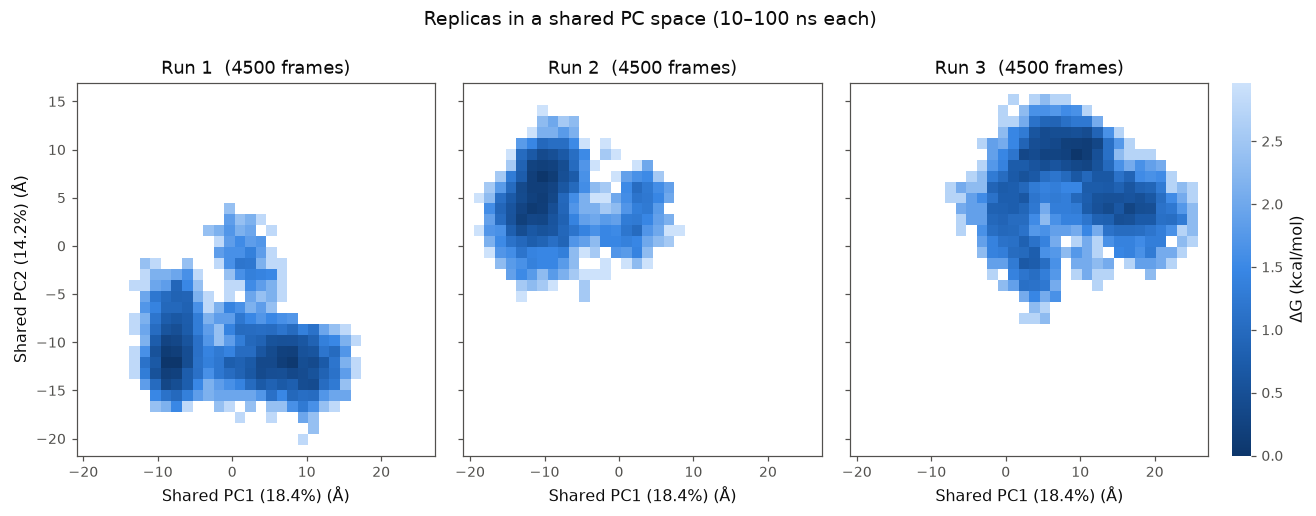

  saved figC2_replica_similarity.png / .pdf


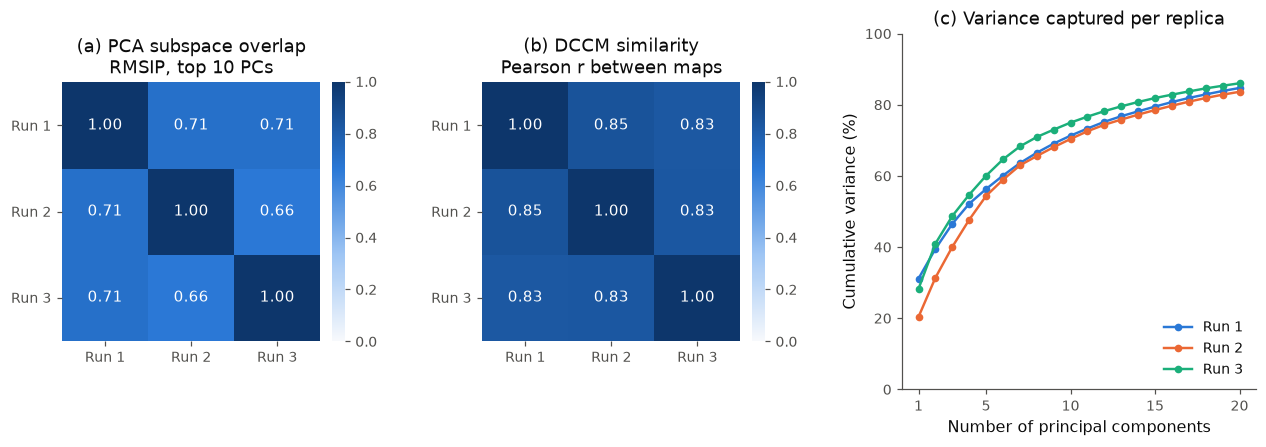

  saved figC3_coupling_by_replica.png / .pdf


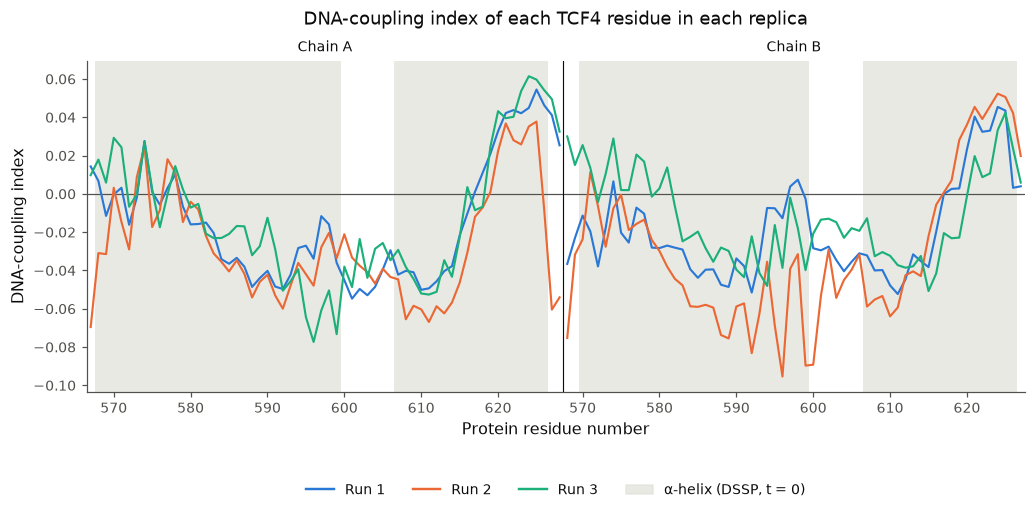

,run,frames,PC1_%,PC2_%,top10_cum_%,chainA-chainB_mean_C,protein-DNA_mean_C,DCCM_split_half_r
0,Run 1,4500,31.2,8.3,71.3,-0.021,-0.017,0.900
1,Run 2,4500,20.4,11.0,70.4,-0.041,-0.028,0.900
2,Run 3,4500,28.3,12.7,75.0,0.007,-0.012,0.808


Between replicas: RMSIP 0.66–0.71; DCCM r 0.83–0.85; landscape overlap (Bhattacharyya, 1 = identical) 0.04–0.15; coupling-profile r 0.60–0.77
Comparison outputs in /deac/phy/classes/phy320-fa-2026/basnl26/Project-1-PHY320620-Fall2026/6od3-2/3/namd/advanced_analysis/comparison


In [16]:
# ---------------------------------------------------------------------------
# 8. Cross-replica comparison (reads only the small node caches of the other runs)
# ---------------------------------------------------------------------------
search_root = WORK_DIR.parent.parent if WORK_DIR.name.lower() == "namd" else WORK_DIR.parent
pattern = (f"*/{WORK_DIR.name}/{OUT_DIR.name}/*_node_trajectory.npz" if WORK_DIR.name.lower() == "namd"
           else f"*/{OUT_DIR.name}/*_node_trajectory.npz")
cache_files = sorted(search_root.glob(pattern))

runs = []
for fpath in cache_files:
    with np.load(fpath, allow_pickle=False) as z:
        meta = json.loads(str(z["meta"]))
        same = (len(z["segid"]) == N_NODES and np.array_equal(z["segid"], as_str(nodes_df.segid))
                and np.array_equal(z["resid"], np.array(nodes_df.resid.tolist()))
                and np.array_equal(z["atom"], as_str(nodes_df.atom)))
        if not same:
            print(f"  skipping {fpath}: different nodes/topology")
            continue
        runs.append({"tag": meta["tag"], "label": meta["run_label"], "coords": np.asarray(z["coords"]),
                     "time": np.asarray(z["time_ns"]), "total_ns": meta.get("total_ns", float(z["time_ns"][-1])),
                     "temperature": meta.get("temperature_K", temperature_K), "path": fpath})
runs.sort(key=lambda r: (0, int(r["label"])) if str(r["label"]).isdigit() else (1, str(r["label"])))

if len(runs) < 2:
    print(f"Found {len(runs)} analysed run(s) under {search_root} ({pattern}).")
    print("Run this notebook in the other run folders, then re-run this cell to compare the replicas.")
else:
    CMP_DIR = OUT_DIR / "comparison"
    CMP_DIR.mkdir(exist_ok=True)
    cmp_end = min([r["time"][-1] for r in runs] + ([ANALYSIS_END_NS] if ANALYSIS_END_NS else []))
    names = [f"Run {r['tag'][3:]}" if r["tag"].lower().startswith("run") else r["tag"] for r in runs]
    run_color = {n: SERIES[k % len(SERIES)] for k, n in enumerate(names)}
    print(f"Comparing {len(runs)} runs over a common window {EQUIL_SKIP_NS:g}–{cmp_end:.2f} ns:")

    # --- each run analysed separately with identical settings ---
    res = []
    for r, name in zip(runs, names):
        w = (r["time"] > EQUIL_SKIP_NS) & (r["time"] <= cmp_end + 1e-9)
        Xr = r["coords"][w].astype(np.float64)
        Xa, mean_r, _ = align_to_average(Xr, fit_idx, ref_nodes)
        Cr = covariance(Xa)
        ev, V = pca_from_cov(Cr)
        Dr = dccm_from_cov(Cr)
        h = len(Xa) // 2
        r_h = np.corrcoef(dccm_from_cov(covariance(Xa[:h]))[iu], dccm_from_cov(covariance(Xa[h:]))[iu])[0, 1]
        res.append(dict(name=name, X=Xr, mean=mean_r, evals=ev, evecs=V, dccm=Dr,
                        coupling=Dr[np.ix_(p_idx, d_idx)].mean(axis=1), frames=len(Xa), half_r=r_h))
        print(f"   {name}: {r['total_ns']:.1f} ns simulated, {len(Xa)} frames used  [{r['path'].relative_to(search_root)}]")

    # --- common orientation: superpose every run's mean on the first run's mean, rotate its eigenvectors ---
    ref_mean = res[0]["mean"]
    for q in res:
        c_q, c_0 = q["mean"][fit_idx].mean(0), ref_mean[fit_idx].mean(0)
        R = kabsch_rotation((q["mean"][fit_idx] - c_q)[None], ref_mean[fit_idx] - c_0)[0]
        q["evecs_common"] = np.einsum("nik,ij->njk", q["evecs"][:, :K].reshape(N, 3, K), R).reshape(3 * N, K)

    nR = len(res)
    RMSIP = np.ones((nR, nR)); DR = np.ones((nR, nR))
    for i in range(nR):
        for j in range(nR):
            if i != j:
                RMSIP[i, j] = rmsip(res[i]["evecs_common"], res[j]["evecs_common"], K)[0]
                DR[i, j] = np.corrcoef(res[i]["dccm"][iu], res[j]["dccm"][iu])[0, 1]

    # --- shared PC space: all frames superposed on one common average (no time-series concatenation) ---
    X_all = np.concatenate([q["X"] for q in res])
    X_all_al, mean_all, _ = align_to_average(X_all, fit_idx, ref_nodes)
    ev_all, V_all = pca_from_cov(covariance(X_all_al))
    frac_all = ev_all / ev_all.sum()
    P_all = (X_all_al - mean_all).reshape(len(X_all_al), 3 * N) @ V_all[:, :2]
    bounds = np.cumsum([0] + [q["frames"] for q in res])
    pad = 0.05 * (P_all.max(0) - P_all.min(0))
    nb = fel_bins(min(q["frames"] for q in res))
    ex = np.linspace(P_all[:, 0].min() - pad[0], P_all[:, 0].max() + pad[0], nb + 1)
    ey = np.linspace(P_all[:, 1].min() - pad[1], P_all[:, 1].max() + pad[1], nb + 1)
    fels, dists = [], []
    for k in range(nR):
        Pk = P_all[bounds[k]:bounds[k + 1]]
        Gk, _, _, Hk = free_energy_2d(Pk[:, 0], Pk[:, 1], temperature_K, edges=(ex, ey))
        fels.append(Gk); dists.append(Hk)
    BC = np.array([[np.sum(np.sqrt(dists[i] * dists[j])) for j in range(nR)] for i in range(nR)])
    gmax = np.nanmax([np.nanmax(g) for g in fels])

    # ---- Figure C1: shared landscape ----
    fig, axes = plt.subplots(1, nR, figsize=(4.3 * nR + 1, 4.4), sharex=True, sharey=True,
                             gridspec_kw=dict(wspace=0.08))
    for k, ax in enumerate(axes):
        pcm = ax.pcolormesh(ex, ey, fels[k], cmap=CMAP_FEL, vmin=0, vmax=gmax, rasterized=True)
        ax.set_title(f"{res[k]['name']}  ({res[k]['frames']} frames)")
        ax.set_xlabel(f"Shared PC1 ({frac_all[0] * 100:.1f}%) (Å)")
        ax.spines["top"].set_visible(True); ax.spines["right"].set_visible(True)
    axes[0].set_ylabel(f"Shared PC2 ({frac_all[1] * 100:.1f}%) (Å)")
    cb = fig.colorbar(pcm, ax=axes, fraction=0.025, pad=0.02); cb.set_label("ΔG (kcal/mol)"); cb.outline.set_visible(False)
    fig.suptitle(f"Replicas in a shared PC space ({EQUIL_SKIP_NS:g}–{cmp_end:.0f} ns each)", y=1.03)
    save_fig(fig, "figC1_shared_pc_landscape", folder=CMP_DIR)
    plt.show()

    # ---- Figure C2: similarity matrices + cumulative variance ----
    fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw=dict(wspace=0.45, width_ratios=[1, 1, 1.25]))
    for ax, M, title in ((axs[0], RMSIP, f"(a) PCA subspace overlap\nRMSIP, top {K} PCs"),
                         (axs[1], DR, "(b) DCCM similarity\nPearson r between maps")):
        im = ax.imshow(M, cmap=CMAP_OVL, vmin=0, vmax=1)
        for i in range(nR):
            for j in range(nR):
                ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=10,
                        color="white" if M[i, j] > 0.6 else INK)
        ax.set_xticks(range(nR)); ax.set_xticklabels(names)
        ax.set_yticks(range(nR)); ax.set_yticklabels(names)
        for s in ax.spines.values():
            s.set_visible(False)
        ax.set_title(title)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).outline.set_visible(False)
    for q in res:
        cf = np.cumsum(q["evals"] / q["evals"].sum())[:20] * 100
        axs[2].plot(np.arange(1, 21), cf, marker="o", ms=4, color=run_color[q["name"]], label=q["name"])
    axs[2].set_ylim(0, 100); axs[2].set_xticks([1, 5, 10, 15, 20])
    axs[2].set_xlabel("Number of principal components"); axs[2].set_ylabel("Cumulative variance (%)")
    axs[2].set_title("(c) Variance captured per replica"); axs[2].legend(loc="lower right")
    save_fig(fig, "figC2_replica_similarity", folder=CMP_DIR)
    plt.show()

    # ---- Figure C3: DNA-coupling index per replica ----
    fig, ax = plt.subplots(figsize=(11, 3.9))
    for a, b in helix_runs(prot_df.ss.values):
        ax.axvspan(a - 0.5, b - 0.5, color=GRID, alpha=0.7, lw=0, zorder=0)
    ax.axhline(0, color=INK2, lw=0.8)
    stack = np.array([q["coupling"] for q in res])
    for info, s, e in chain_spans(prot_df):
        for q in res:
            ax.plot(np.arange(s, e), q["coupling"][s:e], color=run_color[q["name"]], lw=1.4)
        if s:
            ax.axvline(s - 0.5, color=INK, lw=0.7)
        ax.text((s + e - 1) / 2, 1.02, info["short"], transform=mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes),
                ha="center", va="bottom", fontsize=9)
    decorate_axis(ax, "x", prot_df, band=False)
    ax.set_xlim(-0.5, len(prot_df) - 0.5)
    ax.set_xlabel("Protein residue number"); ax.set_ylabel("DNA-coupling index")
    ax.legend(handles=[Line2D([], [], color=run_color[n], lw=1.6, label=n) for n in names]
              + [Patch(color=GRID, alpha=0.7, label="α-helix (DSSP, t = 0)")],
              ncol=nR + 1, loc="upper center", bbox_to_anchor=(0.5, -0.24))
    ax.set_title("DNA-coupling index of each TCF4 residue in each replica", pad=24)
    save_fig(fig, "figC3_coupling_by_replica", folder=CMP_DIR)
    plt.show()

    # ---- tables ----
    tab = pd.DataFrame([{"run": q["name"], "frames": q["frames"],
                         "PC1_%": round(q["evals"][0] / q["evals"].sum() * 100, 1),
                         "PC2_%": round(q["evals"][1] / q["evals"].sum() * 100, 1),
                         f"top{K}_cum_%": round(q["evals"][:K].sum() / q["evals"].sum() * 100, 1),
                         "chainA-chainB_mean_C": round(float(q["dccm"][SEG_INFO[0]["start"]:SEG_INFO[0]["stop"],
                                                                  SEG_INFO[1]["start"]:SEG_INFO[1]["stop"]].mean()), 3)
                         if len(prot_segids) > 1 else np.nan,
                         "protein-DNA_mean_C": round(float(q["dccm"][np.ix_(p_idx, d_idx)].mean()), 3),
                         "DCCM_split_half_r": round(float(q["half_r"]), 3)} for q in res])
    display(tab)
    tab.to_csv(CMP_DIR / "replica_summary.csv", index=False)
    for M, nm in ((RMSIP, "rmsip"), (DR, "dccm_pearson_r"), (BC, "landscape_overlap_bhattacharyya")):
        pd.DataFrame(M, index=names, columns=names).round(4).to_csv(CMP_DIR / f"replica_{nm}.csv")
    off = ~np.eye(nR, dtype=bool)
    r_prof = np.corrcoef(stack)[off]
    print(f"Between replicas: RMSIP {RMSIP[off].min():.2f}–{RMSIP[off].max():.2f}; "
          f"DCCM r {DR[off].min():.2f}–{DR[off].max():.2f}; "
          f"landscape overlap (Bhattacharyya, 1 = identical) {BC[off].min():.2f}–{BC[off].max():.2f}; "
          f"coupling-profile r {r_prof.min():.2f}–{r_prof.max():.2f}")
    print(f"Comparison outputs in {CMP_DIR}")

**Figure C1.** *Pseudo free-energy landscapes of each replica on a shared PC1–PC2 coordinate system (PCA of all replicas' frames after superposition on one common average; same window and colour scale for every run).*

**Figure C2.** *(a) RMSIP between the top-10 PC subspaces of each pair of replicas (each run's own PCA, rotated into a common orientation). (b) Pearson correlation between the replicas' DCCMs. (c) Cumulative variance of each replica's PCA.*

**Figure C3.** *DNA-coupling index of every TCF4 residue, one line per replica; grey bands are α-helices.*

**Interpretation** *:*### Interpretation — Cross-Replica Comparison (Runs 1–3)

**Conformational sampling:** The three replicas occupy largely different regions of the shared PCA landscape, with low Bhattacharyya overlap (**0.04–0.15**), indicating limited sampling of common conformational basins.

**Collective motions:** Moderate PCA subspace overlap (RMSIP = **0.66–0.71**) suggests that the replicas share some essential motions, although their conformational distributions differ.

**DCCM similarity:** High inter-replica correlations (**r = 0.83–0.85**) indicate reproducible overall correlated-motion patterns.

**Protein–DNA coupling:** The coupling profiles show moderate agreement (**r = 0.60–0.77**), with consistently positive coupling near residues 620–625 and predominantly negative coupling in central regions. However, coupling strengths vary between replicas.

**Overall:** The replicas exhibit similar dynamical correlation patterns and partially shared collective motions but sample distinct conformational basins. This suggests that some local coupling features are reproducible, while conformational sampling remains incomplete.

In [17]:
# Save the notebook first (File -> Save), then export an HTML copy tagged with this run's label
!jupyter nbconvert --to html Advanced_Analysis.ipynb --output Advanced_Analysis_{TAG}

[NbConvertApp] WARNING | pattern 'Advanced_Analysis.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
--execu